The purpose of this notebook to create the insertion pipeline
The tool receives the multiple views of general object and a prompt to generate new object

imports

In [179]:
from pathlib import Path
import os
from ObjaverseDataset import ObjaverseDataset
from torch.utils.data import DataLoader
from pathlib import Path

from prompts import *
from utils import _convert_trimesh_to_o3d

# Keep relative input and output paths anchored at the project root.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()
if not (PROJECT_ROOT / "utils.py").is_file():
    raise RuntimeError(f"Open this notebook from the project root or experiments/: {Path.cwd()}")
os.chdir(PROJECT_ROOT)

from utils import *

### 0. Ojbect preparation

In [180]:
objaverse_dataset = ObjaverseDataset(category="duck", limit=1)
objaverse_dataloader = DataLoader(objaverse_dataset, batch_size=1, shuffle=False, collate_fn=objaverse_dataset.collate_fn)

dict_keys(['Band_Aid', 'Bible', 'CD_player', 'Christmas_tree', 'Dixie_cup', 'Ferris_wheel', 'Lego', 'Rollerblade', 'Sharpie', 'Tabasco_sauce', 'aerosol_can', 'air_conditioner', 'airplane', 'alarm_clock', 'alcohol', 'alligator', 'almond', 'ambulance', 'amplifier', 'anklet', 'antenna', 'apple', 'apricot', 'apron', 'aquarium', 'arctic_(type_of_shoe)', 'armband', 'armchair', 'armoire', 'armor', 'army_tank', 'artichoke', 'ashtray', 'asparagus', 'atomizer', 'automatic_washer', 'avocado', 'award', 'awning', 'ax', 'baboon', 'baby_buggy', 'backpack', 'bagel', 'baguet', 'bait', 'ball', 'ballet_skirt', 'balloon', 'bamboo', 'banana', 'bandage', 'bandanna', 'banjo', 'banner', 'barbell', 'barge', 'barrel', 'barrow', 'baseball', 'baseball_bat', 'baseball_cap', 'baseball_glove', 'basket', 'basketball', 'basketball_backboard', 'bass_horn', 'bat_(animal)', 'bath_mat', 'bath_towel', 'bathrobe', 'bathtub', 'battery', 'beachball', 'bead', 'beanbag', 'beanie', 'bear', 'bed', 'bedpan', 'bedspread', 'beef_(fo

In [181]:
current_object = objaverse_dataset[0] # obj_path, vertices, faces
mesh = current_object["mesh"]
mesh.show()

=== Processing UID: b5c9d06f19be4c92a1708515f6655573 ===
FEngine (64 bits) created at 0x12cfddc00 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1


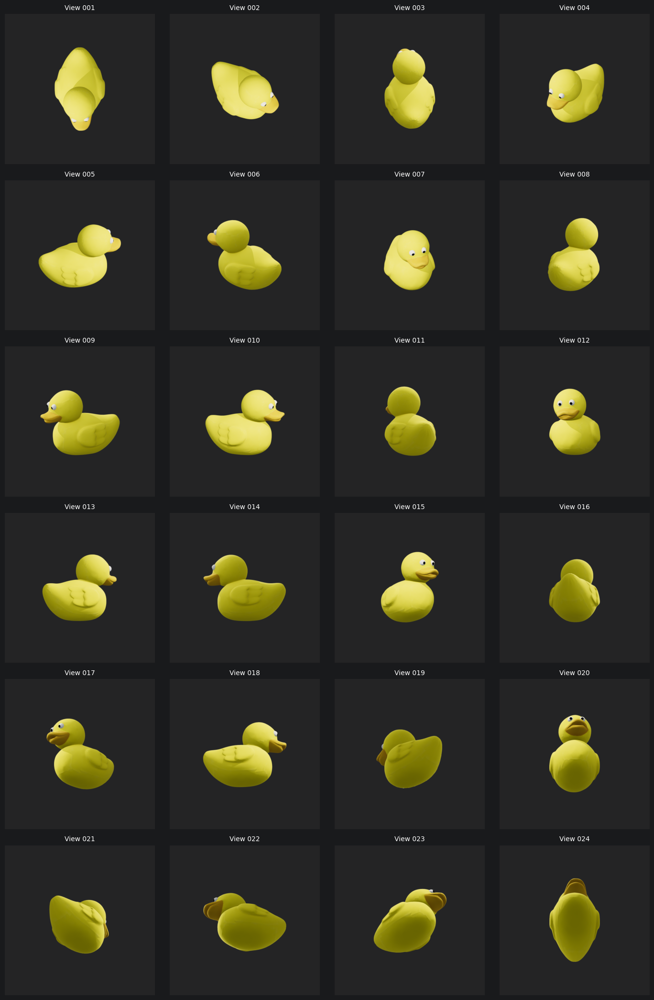

In [182]:
uid_value = current_object["uid"]
uid = uid_value[0] if isinstance(uid_value, (list, tuple)) else uid_value
print(f"=== Processing UID: {uid} ===")
mesh = current_object["mesh"][0] if isinstance(current_object["mesh"], list) else current_object["mesh"]
output_dir = f"rendered_views/{uid}"
rendered_info = render_n_views(mesh, n_views=24, output_dir=output_dir, frame_scale=1.8)
show_rendered_grid(output_dir)

#### 0.1) Input.
Now, the tool should receive the prompt which object should be generated

In [183]:
# prompt = "left bunny ear"
prompt = "car wheel" # what should be generated
directions = ["left"] # where should it be put
rendered_info = rendered_info # all views
image_path = f"generated_images/Flux2_dev_00012_.png" # path of image for 3d object (used for naming)
new_object_mesh_path = "generated_models/ComfyUI_00032.glb" # path to 3d object

Now the 3d object for the prompt should be generated

In [184]:
# image_path = generate_image_from_text(prompt)
# new_object_mesh_path = generate_3d_object_from_image(image_path)
# new_object_mesh = trimesh.load(new_object_mesh_path)



In [185]:
# new_object_mesh.show()

### 1) Now, render new object from 6 views to give agent a better understanding about the structure of new object

FEngine (64 bits) created at 0x12d692200 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1


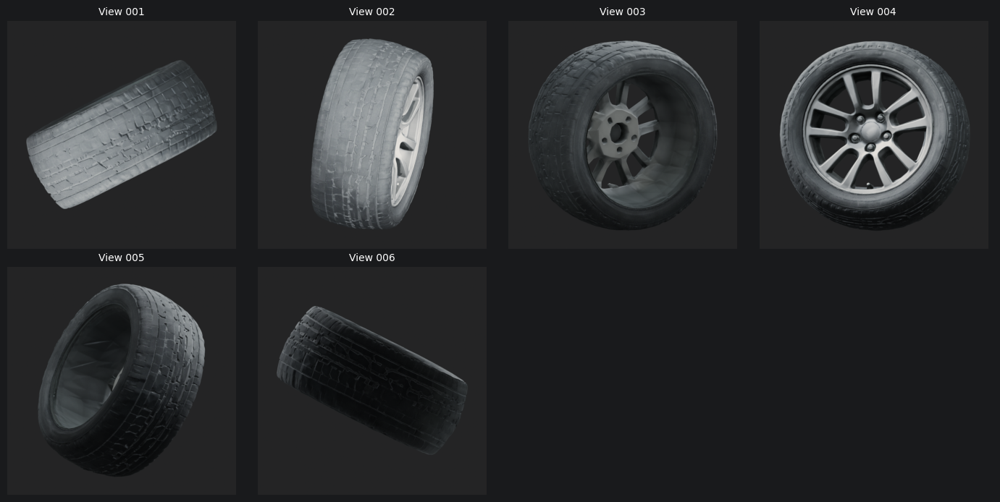

In [186]:
output_dir = f"rendered_new_object_views/{Path(image_path).stem}"
new_object_mesh = trimesh.load("generated_models/ComfyUI_00032.glb")
rendered_new_object_info = render_n_views(new_object_mesh, n_views=6, output_dir=output_dir, is_objaverse_model=False)
show_rendered_grid(output_dir)

### 2) Figure out the center of figure and give each view a direction (left, up, left-up, etc.

We have to give each view a direction from: front, left, right, back, up, down, back-right-up, front-left-down, front-up-left, etc

Since objects may not be aligned in the way that the model will always be rendered from forward, but may be rotated, we ask a VLM to choose from all view the view which the most fits "forward" view. From this based on eyes we can give direction to all other views

In [187]:
FRONT_VIEW_SELECTION_SYSTEM_PROMPT = """
You are a visual reasoning model for 3D object editing.

The input image contains numbered views of the
same 3D object from different camera positions.

Identify the view that most directly shows
the object's intrinsic front side.

The object may have an arbitrary 3D orientation.
Do not assume that it is standing upright.

Compare all views and identify characteristic
features that indicate the object's front.

Return a JSON object with the following fields:
- reasoning: a brief explanation of your selection.
- front_view: the integer ID of the selected view.
"""

In [188]:
from PIL import ImageDraw
def create_views_grid(rendered_info, cols=6, size=320):
    """
    Create a numbered grid of rendered views. So that model has access to all views at the same time
    """

    rows = math.ceil(len(rendered_info) / cols)

    grid = Image.new(
        "RGB",
        (cols * size, rows * (size + 30)),
        (35, 35, 35)
    )

    draw = ImageDraw.Draw(grid)

    for i, (_, path) in enumerate(rendered_info):
        image = Image.open(path).convert("RGB")
        image = image.resize((size, size))

        x = (i % cols) * size
        y = (i // cols) * (size + 30)

        grid.paste(image, (x, y + 30))
        draw.text(
            (x + 10, y + 8),
            f"View {i + 1:03d}",
            fill="white"
        )

    return grid

In [189]:
def estimate_object_orientation(
    mesh,
    rendered_info,
    grid_path,
    ollama_host,
    model_name="qwen3-vl:8b-instruct"
):
    """Estimate object-centric coordinate axes."""

    client = ollama.Client(host=ollama_host)

    response = client.chat(
        model=model_name,
        messages=[
            {
                "role": "system",
                "content": FRONT_VIEW_SELECTION_SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": "Identify the most frontal view.",
                "images": [str(grid_path)]
            }
        ],
        format="json",
        options={
            "temperature": 0.05,
            "num_ctx": 16384
        }
    )

    result = json.loads(response["message"]["content"])
    print("VLM response:", result)

    front_idx = int(result["front_view"]) - 1

    # display(Image.open(rendered_info[front_idx][1]))

    if not 0 <= front_idx < len(rendered_info):
        raise ValueError("Invalid front view index")

    # Use the same mesh center as the renderer
    mesh_o3d = _convert_trimesh_to_o3d(mesh)
    center = mesh_o3d.get_axis_aligned_bounding_box().get_center()

    eye_pos, _ = rendered_info[front_idx]

    # Assume Y-up orientation
    up = np.array([0., 1., 0.])

    # Project front direction onto the horizontal plane
    front = np.asarray(eye_pos) - center
    front -= np.dot(front, up) * up

    if np.linalg.norm(front) < 1e-8:
        raise ValueError("Invalid frontal camera direction")

    front /= np.linalg.norm(front)

    # Compute anatomical directions
    left = np.cross(up, front)
    left /= np.linalg.norm(left)

    return {
        "center": center,
        "front_view_idx": front_idx,
        "front": front,
        "back": -front,
        "left": left,
        "right": -left,
        "up": up,
        "down": -up
    }

In [190]:
def classify_views(rendered_info, orientation, threshold=0.35):
    """
    Classify camera views using object-centric axes. No VLM is used
    Example output:
    {
    "index": 8,
    "eye_pos": array([1.8, 0.9, 1.2]),
    "path": "rendered_views/view_009.png",
    "labels": ["front", "left", "up"],
    "scores": {
        "front": 0.51,
        "back": -0.51,
        "left": 0.77,
        "right": -0.77,
        "up": 0.38,
        "down": -0.38
    }
}
    """

    directions = [
        "front", "back",
        "left", "right",
        "up", "down"
    ]

    center = orientation["center"]
    classified_views = []

    for i, (eye_pos, path) in enumerate(rendered_info):

        camera_dir = np.asarray(eye_pos) - center
        camera_dir /= np.linalg.norm(camera_dir)
        # scores of each direction are decided by dot product with orientation vector
        scores = {
            name: float(np.dot(camera_dir, orientation[name]))
            for name in directions
        }

        labels = [
            name for name in directions
            if scores[name] >= threshold
        ]

        classified_views.append({
            "index": i,
            "eye_pos": eye_pos,
            "path": path,
            "labels": labels,
            "scores": scores
        })

    return classified_views

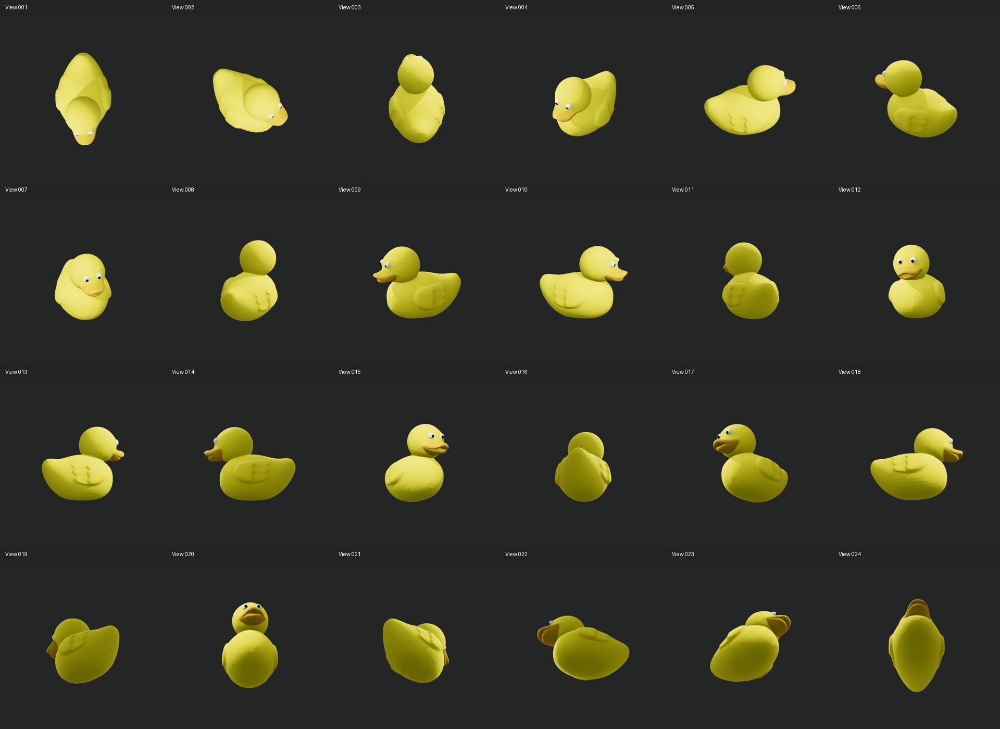

In [191]:
views_grid = create_views_grid(rendered_info)
views_grid.save("views_grid.png")

display(views_grid)

VLM response: {'reasoning': "The most frontal view is the one where the duck's face is directly facing the camera, showing its eyes and beak clearly. View015 is the most frontal view because it shows the duck's face directly towards the viewer, with the beak and eyes centered in the frame, indicating the front side of the object.", 'front_view': 15}
Front view: 15


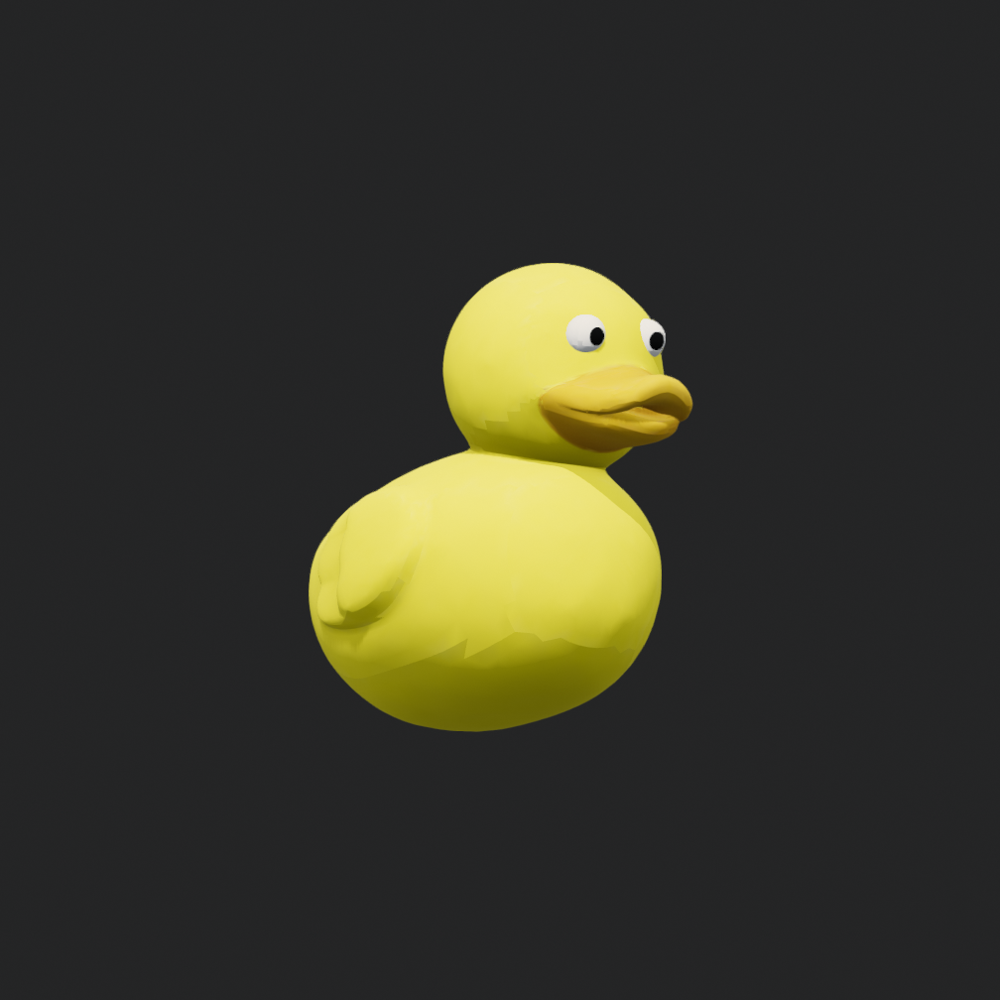

In [192]:
orientation = estimate_object_orientation(
    mesh,
    rendered_info,
    grid_path="views_grid.png",
    ollama_host="192.168.178.23"
)

front_idx = orientation["front_view_idx"]

print(f"Front view: {front_idx + 1}")

display(Image.open(rendered_info[front_idx][1]))

In [193]:
classified_views = classify_views(
    rendered_info,
    orientation
)

for view in classified_views:
    print(
        f"View {view['index'] + 1:03d}: "
        f"{'-'.join(view['labels'])}"
    )

View 001: up
View 002: front-up
View 003: back-up
View 004: left-up
View 005: right-up
View 006: back-up
View 007: front-up
View 008: back-right-up
View 009: left
View 010: front-right
View 011: back
View 012: front-left
View 013: right
View 014: back-left
View 015: front
View 016: back-right
View 017: left-down
View 018: front-right-down
View 019: back-down
View 020: front-left-down
View 021: right-down
View 022: left-down
View 023: front-down
View 024: down


### 3) Select only relevant views for atachment point

In [194]:
def select_relevant_views(
    classified_views,
    directions,
    threshold=0.35,
    max_views=6
):
    """
    Select and rank views matching all requested directions.
    Selection is based on scores for each direction and not labels
    """

    relevant_views = []

    for view in classified_views:
        scores = [
            view["scores"][direction]
            for direction in directions
        ]

        # Check all spatial constraints
        if all(score >= threshold for score in scores):

            relevance = np.mean(scores)

            relevant_views.append(
                (view["index"], relevance)
            )

    # Sort views by relevance
    relevant_views.sort(
        key=lambda item: item[1],
        reverse=True
    )

    return [
        index for index, score
        in relevant_views[:max_views]
    ]

In [195]:
selected_views = select_relevant_views(
    classified_views,
    directions=directions,
    threshold=0.3
)

print("Selected views:")

for i in selected_views:
    print(
        f"View {i + 1:03d}: "
        f"{'-'.join(classified_views[i]['labels'])}"
    )

Selected views:
View 009: left
View 017: left-down
View 012: front-left
View 014: back-left
View 004: left-up
View 022: left-down


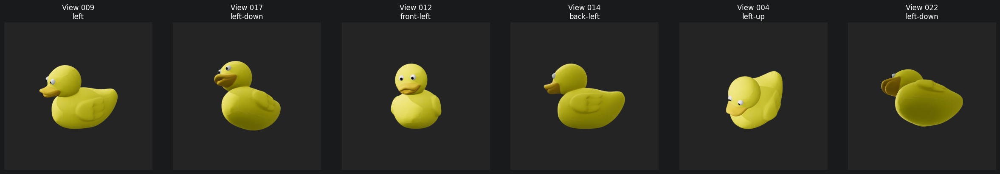

In [196]:
if selected_views:
    fig, axes = plt.subplots(
        1,
        len(selected_views),
        figsize=(4 * len(selected_views), 4),
        squeeze=False
    )

    for ax, i in zip(axes.flat, selected_views):
        view = classified_views[i]

        ax.imshow(Image.open(view["path"]))
        ax.set_title(
            f"View {i + 1:03d}\n"
            f"{'-'.join(view['labels'])}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No relevant views found")

### 4) Generate the attachment point

In [197]:

ATTACHMENT_POINT_SYSTEM_PROMPT = """
You are a visual reasoning model for 3D object editing.

Image 1 shows the original object.
The remaining images show the component to attach.

Imagine the component attached to the original object
according to the user's instructions.

Predict the single point on the original object's
surface where the new component should connect.

The point represents the center of the contact area
between the two objects.

Return coordinates relative to Image 1 only.
Use integer coordinates normalized to [0, 1000].

Return a JSON object with the following fields:
- is_found: boolean
- point_2d: [x, y] or null if not found
"""
def generate_attachment_point(
    ollama_host,
    image_path,
    user_prompt,
    rendered_new_object_info,
    model_name="qwen3-vl:8b-instruct"
):
    """Predict a surface attachment point."""
    reference_images = [element[1] for element in rendered_new_object_info]
    with Image.open(image_path) as image:
        width, height = image.size

    client = ollama.Client(host=ollama_host)

    response = client.chat(
        model=model_name,
        messages=[
            {
                "role": "system",
                "content": ATTACHMENT_POINT_SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": user_prompt,
                "images": [
                    str(image_path),
                    *[str(path) for path in reference_images]
                ]
            }
        ],
        format="json",
        options={
            "temperature": 0.1,
            "num_ctx": 16384,
            "num_predict": 256
        }
    )

    result = json.loads(response["message"]["content"])

    if not result["is_found"]:
        return None

    x, y = result["point_2d"]

    return (
        round(x / 1000 * (width - 1)),
        round(y / 1000 * (height - 1))
    )


In [198]:
def pixel_to_3d(
    mesh,
    point_2d,
    eye_pos,
    width=1008,
    height=1008,
    frame_scale=1.8
):
    """
    Project a 2D pixel onto the mesh surface using raycasting.
    """

    # Use the same geometry as in render_n_views
    mesh_o3d = _convert_trimesh_to_o3d(mesh)

    bbox = mesh_o3d.get_axis_aligned_bounding_box()
    center = bbox.get_center()
    extent = bbox.get_max_extent()

    half_size = extent / 2 * frame_scale
    aspect = width / height

    # Camera coordinate system
    z_cam = eye_pos - center
    z_cam /= np.linalg.norm(z_cam)

    if abs(z_cam[1]) > 0.99:
        up = np.array([0, 0, -1 if z_cam[1] > 0 else 1])
    else:
        up = np.array([0, 1, 0])

    x_cam = np.cross(up, z_cam)
    x_cam /= np.linalg.norm(x_cam)
    y_cam = np.cross(z_cam, x_cam)

    # Convert pixel coordinates to orthographic coordinates
    px, py = point_2d

    x = (2 * (px + 0.5) / width - 1) * half_size * aspect
    y = (1 - 2 * (py + 0.5) / height) * half_size

    # Construct an orthographic ray
    origin = eye_pos + x * x_cam + y * y_cam
    direction = -z_cam

    ray_mesh = o3d.t.geometry.TriangleMesh.from_legacy(mesh_o3d)

    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(ray_mesh)

    ray = np.concatenate([origin, direction])
    rays = o3d.core.Tensor([ray], dtype=o3d.core.Dtype.Float32)

    hits = scene.cast_rays(rays)

    t_hit = hits["t_hit"].numpy()[0]

    if not np.isfinite(t_hit):
        return None, None

    anchor_point = origin + t_hit * direction
    anchor_normal = hits["primitive_normals"].numpy()[0]

    return anchor_point, anchor_normal


In [199]:
def validate_anchor_point(
    point,
    orientation,
    directions
):
    """
    Check whether a point satisfies spatial constraints.
    """

    relative_point = point - orientation["center"]

    return all(
        np.dot(relative_point, orientation[d]) >= 0
        for d in directions
    )


View 9
2D point: (440, 631)


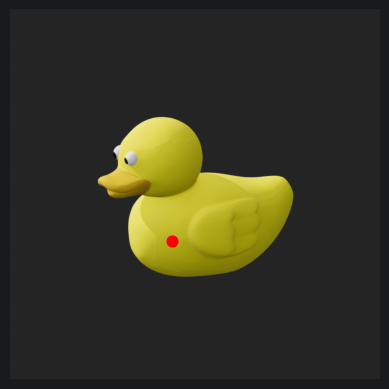

3D point: [ 0.21510044 -0.079117    0.19566107]

View 17
2D point: (440, 592)


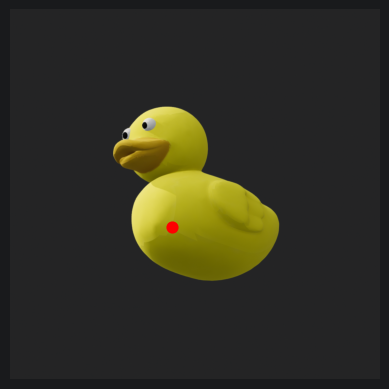

3D point: [ 0.12827885 -0.20959032  0.25247402]

View 12
2D point: (478, 629)


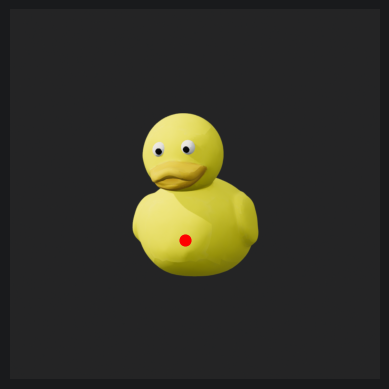

3D point: [ 0.05347255 -0.13659019  0.31711109]

View 14
2D point: (470, 591)


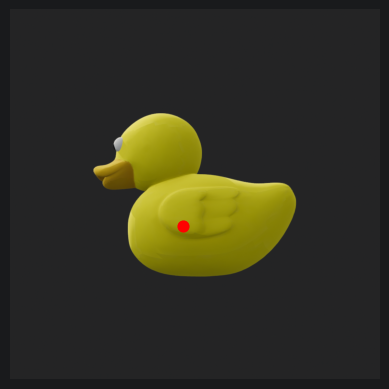

3D point: [ 0.30118145 -0.12261076 -0.00818006]

View 4
2D point: (478, 655)


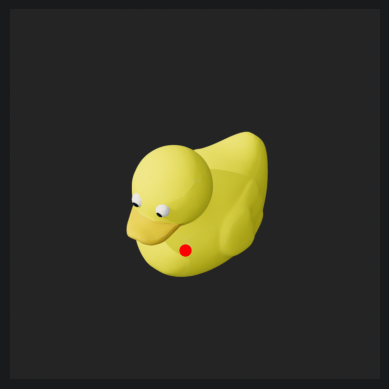

3D point: [ 0.14473998 -0.0029132   0.25938285]

View 22
2D point: (453, 629)


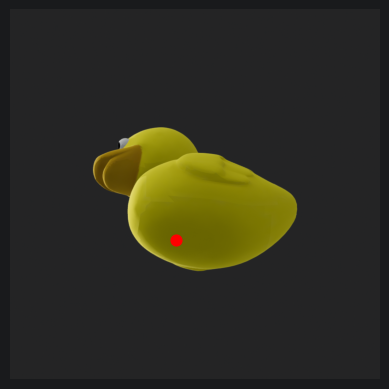

3D point: [-0.01316865 -0.32125184  0.08576392]
Valid points: 6/24


In [200]:
#TODO: replace hardcoded enhanced prompt with llm request
enhanced_prompt = """
Locate the attachment point for a car wheel
below the visible wing, slightly toward the chest,
on the lower body of the duck.
"""
# we should enhance the prompt via other LLM for better performance

N_BASE_VIEWS = 24
N_PART_VIEWS = 6
FRAME_SCALE = 1.8
OLLAMA_HOST = "192.168.178.23"

anchor_points = []
anchor_normals = []

for i in selected_views:
    eye_pos, view_path = rendered_info[i]

    point_2d = generate_attachment_point(
        ollama_host="192.168.178.23",
        image_path=view_path,
        rendered_new_object_info = rendered_new_object_info,
        user_prompt=enhanced_prompt
    )

    print(f"\nView {i + 1}")
    print("2D point:", point_2d)

    if point_2d is None:
        print("VLM rejected this view")
        continue

    plt.imshow(Image.open(view_path))
    plt.scatter(*point_2d, c="red", s=60)
    plt.axis("off")
    plt.show()

    point_3d, normal = pixel_to_3d(
        mesh,
        point_2d,
        eye_pos,
        frame_scale=1.8
    )

    # if not validate_anchor_point(
    #     point_3d,
    #     orientation,
    #     directions
    # ):
    #     print("Point violates spatial constraints")
    #     continue

    if point_3d is None:
        print("Raycasting missed the mesh")
        continue

    print("3D point:", point_3d)

    anchor_points.append(point_3d)
    anchor_normals.append(normal)

    # plt.imshow(Image.open(view_path))
    # plt.scatter(*point_2d, c="red", s=60)
    # plt.axis("off")
    # plt.show()

anchor_points = np.asarray(anchor_points)
anchor_normals = np.asarray(anchor_normals)

print(f"Valid points: {len(anchor_points)}/{len(rendered_info)}")

In [201]:
scene = trimesh.Scene([mesh])

for point in anchor_points:
    sphere = trimesh.creation.icosphere(
        radius=mesh.extents.max() * 0.015
    )

    sphere.apply_translation(point)
    sphere.visual.face_colors = [255, 0, 0, 255]

    scene.add_geometry(sphere)

scene.show()

In [202]:
from sklearn.cluster import DBSCAN

if len(anchor_points) < 1:
    raise ValueError("Not enough valid anchor points")

labels = DBSCAN(
    eps=mesh.extents.max() * 0.2,
    min_samples=3
).fit_predict(anchor_points)

valid_labels = labels[labels != -1]

if len(valid_labels) == 0:
    raise ValueError("No consistent attachment region found")

best_label = np.bincount(valid_labels).argmax()
indices = np.where(labels == best_label)[0]

cluster_points = anchor_points[indices]
center = cluster_points.mean(axis=0)

# Select the closest actual surface point
best_idx = indices[
    np.argmin(np.linalg.norm(cluster_points - center, axis=1))
]

anchor_point = anchor_points[best_idx]
anchor_normal = anchor_normals[best_idx]

In [203]:
if anchor_point is not None:
    sphere = trimesh.creation.icosphere(
        subdivisions=3,
        radius=mesh.extents.max() * 0.025
    )

    sphere.apply_translation(anchor_point)
    sphere.visual.face_colors = [255, 0, 0, 255]

    scene = trimesh.Scene([mesh, sphere])
    scene.show()

In [204]:
scene.show()

### 5) Generate bounding boxes for object including attachment point

#### Render of model including attachment points

In [205]:
INSERTION_BOUNDING_BOX_SYSTEM_PROMPT = """
Image 1 shows a 3D object with a red attachment marker.
The remaining images show the component to insert.

Imagine the new component attached to the object
at the red marker.

Predict the bounding box of the entire imagined
component, including its occluded portions.

The bounding box may overlap the original object
and extend into the background.

Estimate a suitable size and orientation.

Return coordinates relative to Image 1 only,
using integer coordinates normalized to [0, 1000].

Return only JSON with the following fields:
- is_found: boolean
- bbox_2d: [xmin, ymin, xmax, ymax]

Return is_found=false only if the placement
cannot be estimated at all.
"""


RELATIVE_INSERTION_BBOX_SYSTEM_PROMPT = """
You are a spatial reasoning model for 3D object insertion.

Image 1 shows the original object with an attachment marker.
The remaining images show different views of the component
to be inserted.

Imagine the component physically attached at the given anchor.

The reference images illustrate the component's shape
and appearance, NOT its intended scale.
The component was rendered independently.
Do not transfer its apparent size from the reference images.

Consider:
- The geometry and proportions of the inserted component.
- Its natural size relative to the original object.
- Its orientation after attachment.
- The current camera viewing angle.
- The user request.

Predict the tightest bounding box of the entire imagined
component, including its occluded portions.

The bounding box must contain the attachment anchor,
but the anchor is not necessarily its center.

Do not assume a square bounding box.
Account for the current viewing angle.
Do not surround the original object.

Return absolute image coordinates as integers
normalized to [0, 1000].

Return only JSON:
{
    "xmin": integer,
    "ymin": integer,
    "xmax": integer,
    "ymax": integer
}
"""

In [206]:
def _auto_camera_up(center, eye):
    """
    Place camera to the up
    :param center:
    :param eye:
    :return:
    """
    eye = np.asarray(eye, dtype=float)
    center = np.asarray(center, dtype=float)

    z_cam = eye - center
    z_cam /= np.linalg.norm(z_cam)

    if abs(z_cam[1]) > 0.99:
        return np.array([0.0, 0.0, -1.0]) if z_cam[1] > 0 else np.array([0.0, 0.0, 1.0])
    return np.array([0.0, 1.0, 0.0])

In [207]:
def rendered_info_to_views(mesh_input, rendered_info):
    """
    Converts rendered info to {
        "view_001": (eye_pos, up),
        "view_002": (eye_pos, up),
        ...
    }
    :param mesh_input:
    :param rendered_info:
    :return:
    """
    if isinstance(mesh_input, trimesh.Scene):
        tmesh = mesh_input.dump(concatenate=True)
        mesh_o3d = _convert_trimesh_to_o3d(tmesh, is_objaverse_model=False)
    elif isinstance(mesh_input, trimesh.Trimesh):
        mesh_o3d = _convert_trimesh_to_o3d(mesh_input, is_objaverse_model=False)
    elif isinstance(mesh_input, str):
        mesh_o3d = o3d.io.read_triangle_mesh(mesh_input)
    else:
        mesh_o3d = mesh_input

    center = mesh_o3d.get_axis_aligned_bounding_box().get_center()

    views = {}
    for idx, (eye, _) in enumerate(rendered_info):
        eye = np.asarray(eye, dtype=float)
        up = _auto_camera_up(center, eye)
        views[f"view_{idx + 1:03d}"] = (eye, up)

    return views

In [208]:
def rerender_scene_with_anchor(
    mesh,
    anchor_point,
    rendered_info,
    output_dir="rendered_anchor_views",
    width=1008,
    height=1008,
    frame_scale=1.8,
    marker_radius_ratio=0.025,
):
    """Render the original mesh with a red attachment marker."""

    # Convert the original mesh while preserving colors
    base_mesh = _convert_trimesh_to_o3d(mesh)

    bbox = base_mesh.get_axis_aligned_bounding_box()
    extent = bbox.get_max_extent()

    # Create a red anchor marker
    marker = o3d.geometry.TriangleMesh.create_sphere(
        radius=extent * marker_radius_ratio
    )

    marker.translate(anchor_point)
    marker.paint_uniform_color([1.0, 0.0, 0.0])
    marker.compute_vertex_normals()

    # Combine geometries after color conversion
    scene = base_mesh + marker

    # Restore original camera positions
    views = rendered_info_to_views(base_mesh, rendered_info)

    return render_n_views(
        scene,
        output_dir=output_dir,
        width=width,
        height=height,
        views=views,
        frame_scale=frame_scale,
        is_objaverse_model=False
    )

In [209]:
def _parse_qwen_bbox_response(content, width, height):
    """
    Parses VLM response to collect bounding box coordinates
    :param content:
    :param width:
    :param height:
    :return:
    """
    try:
        result = json.loads(content)
    except json.JSONDecodeError as exc:
        raise ValueError(f"Invalid JSON: {content[:500]!r}") from exc

    if not isinstance(result, dict):
        raise ValueError(f"Invalid response type: {type(result)}")

    if type(result.get("is_found")) is not bool:
        raise ValueError(f"Missing/invalid is_found: {result}")

    if result["is_found"] is False:
        return {"is_found": False, "bbox_2d": None}

    bbox = result.get("bbox_2d")
    if not isinstance(bbox, (list, tuple)) or len(bbox) != 4:
        raise ValueError(f"Invalid bbox_2d: {bbox}")

    coords = [float(v) for v in bbox]

    if not all(0 <= v <= 1000 for v in coords):
        raise ValueError(f"Coordinates outside [0,1000]: {bbox}")

    x1, y1, x2, y2 = coords
    x1 = round(x1 * width / 1000)
    y1 = round(y1 * height / 1000)
    x2 = round(x2 * width / 1000)
    y2 = round(y2 * height / 1000)

    x1 = max(0, min(width - 1, x1))
    y1 = max(0, min(height - 1, y1))
    x2 = max(0, min(width - 1, x2))
    y2 = max(0, min(height - 1, y2))

    if x1 >= x2 or y1 >= y2:
        raise ValueError(f"Collapsed/inverted bbox: {[x1, y1, x2, y2]}")

    return {"is_found": True, "bbox_2d": [x1, y1, x2, y2]}

In [210]:
def generate_insertion_bounding_box_for_image(
    ollama_host,
    image_path,
    inserted_object_image_paths,
    user_prompt,
    model_name="qwen3-vl:8b-instruct",
    temperature=0.1,
    num_ctx=16384,
    max_reference_views=3,
):
    """
    Generates bounding box for one view
    :param ollama_host: ip of server with ollama
    :param image_path: path to view
    :param inserted_object_image_paths: paths to object that should be added
    :param user_prompt: prompt given to the tool
    :param model_name: name of the VLM model
    :param temperature:
    :param num_ctx:
    :param max_reference_views:
    :return:
    """
    with Image.open(image_path) as image:
        width, height = image.size

    reference_paths = [str(p) for p in inserted_object_image_paths[:max_reference_views]]
    images = [str(image_path)] + reference_paths

    content = f"""
    Image 1 shows the target object with a red anchor marker.
    The new component must be attached at the red marker.

    User request:
    {user_prompt}

    Return a bounding box for the imagined inserted component only in Image 1.
    If this view is not suitable or the placement cannot be estimated reliably, return is_found=false.
    """

    client = ollama.Client(host=ollama_host)

    response = client.chat(
        model=model_name,
        messages=[
            {
                "role": "system",
                "content": INSERTION_BOUNDING_BOX_SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": content,
                "images": images
            }
        ],
        format="json",
        think=False,
        options={
            "temperature": temperature,
            "num_ctx": num_ctx
        }
    )

    parsed = _parse_qwen_bbox_response(
        response["message"]["content"],
        width=width,
        height=height
    )

    return json.dumps(parsed)

In [211]:
def generate_insertion_bounding_boxes(
    ollama_host,
    rendered_anchor_info,
    inserted_object_image_paths,
    user_prompt,
    model_name="qwen3-vl:8b-instruct",
    temperature=0.1,
    num_ctx=16384,
    max_reference_views=3,
):
    """
    Generates bounding box for each view
    :param ollama_host:
    :param rendered_anchor_info:
    :param inserted_object_image_paths:
    :param user_prompt:
    :param model_name:
    :param temperature:
    :param num_ctx:
    :param max_reference_views:
    :return:
    """
    results = []

    for view_idx, (eye_pos, image_path) in enumerate(rendered_anchor_info):
        try:
            raw = generate_insertion_bounding_box_for_image(
                ollama_host=ollama_host,
                image_path=image_path,
                inserted_object_image_paths=inserted_object_image_paths,
                user_prompt=user_prompt,
                model_name=model_name,
                temperature=temperature,
                num_ctx=num_ctx,
                max_reference_views=max_reference_views,
            )
            parsed = json.loads(raw)
        except Exception as exc:
            parsed = {
                "is_found": False,
                "bbox_2d": None,
                "error": str(exc),
            }

        parsed["view_idx"] = view_idx
        parsed["eye_pos"] = np.asarray(eye_pos).tolist()
        parsed["image_path"] = image_path
        results.append(parsed)

    return results

In [212]:
def visualize_bbox_result(image_path, bbox_result):
    """
    Visualizes bounding box result
    :param image_path:
    :param bbox_result:
    :return:
    """
    image = np.array(Image.open(image_path).convert("RGB"))

    plt.figure(figsize=(8, 8))
    plt.imshow(image)

    if bbox_result.get("is_found") and bbox_result.get("bbox_2d") is not None:
        x1, y1, x2, y2 = bbox_result["bbox_2d"]
        plt.gca().add_patch(
            plt.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                edgecolor="yellow",
                facecolor="none",
                linewidth=2
            )
        )

    plt.axis("off")
    plt.show()

In [213]:
anchor_rendered_info = rerender_scene_with_anchor(
    mesh=mesh,
    anchor_point=anchor_point,
    rendered_info=rendered_info,
    output_dir="rendered_anchor_views",
    frame_scale=1.8,
)
anchor_rendered_info

FEngine (64 bits) created at 0x12d4a3c00 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1


[(array([ 6.75043758e-04,  2.27373376e+00, -3.36460363e-03]),
  'rendered_anchor_views/view_001.png'),
 (array([-0.66096379,  2.08242941,  0.60275076]),
  'rendered_anchor_views/view_002.png'),
 (array([ 0.10906492,  1.89112506, -1.23841136]),
  'rendered_anchor_views/view_003.png'),
 (array([0.90228232, 1.69982071, 1.17262244]),
  'rendered_anchor_views/view_004.png'),
 (array([-1.64158347,  1.50851637, -0.29385701]),
  'rendered_anchor_views/view_005.png'),
 (array([ 1.53198324,  1.31721202, -0.97745753]),
  'rendered_anchor_views/view_006.png'),
 (array([-0.50090104,  1.12590767,  1.86247341]),
  'rendered_anchor_views/view_007.png'),
 (array([-0.93246576,  0.93460332, -1.80007043]),
  'rendered_anchor_views/view_008.png'),
 (array([1.96914881, 0.74329897, 0.71551886]),
  'rendered_anchor_views/view_009.png'),
 (array([-1.98425164,  0.55199463,  0.81598428]),
  'rendered_anchor_views/view_010.png'),
 (array([ 0.92517012,  0.36069028, -1.97895687]),
  'rendered_anchor_views/view_011.

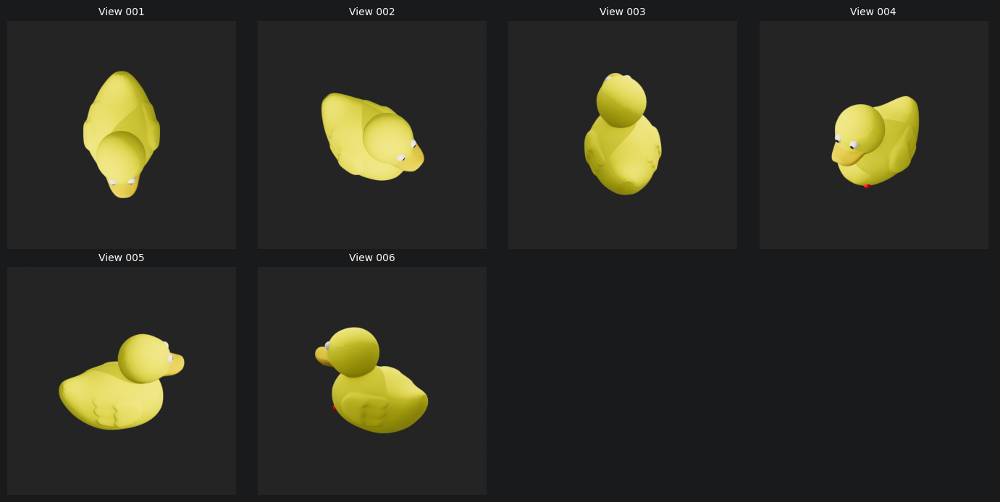

In [214]:
output_dir = f"rendered_anchor_views"
show_rendered_grid(output_dir,6)

In [215]:
inserted_object_image_paths = [
    path for _, path in rendered_new_object_info[:3]
]

In [216]:
bbox_prompt = """
Imagine a single car wheel mounted on the duck
at the red marker.

Predict the rectangular image region that would
be occupied by the wheel after insertion.

The wheel is smaller than the duck.
The wheel touches the red marker.

Do not detect or surround the duck itself.
"""
bbox_results = generate_insertion_bounding_boxes(
    ollama_host="192.168.178.23",
    rendered_anchor_info=anchor_rendered_info,
    inserted_object_image_paths=inserted_object_image_paths,
    user_prompt=bbox_prompt,
    max_reference_views=3,
    num_ctx=16384,
)

Valid bbox predictions: 24/24
View 001 -> [333, 484, 665, 786]


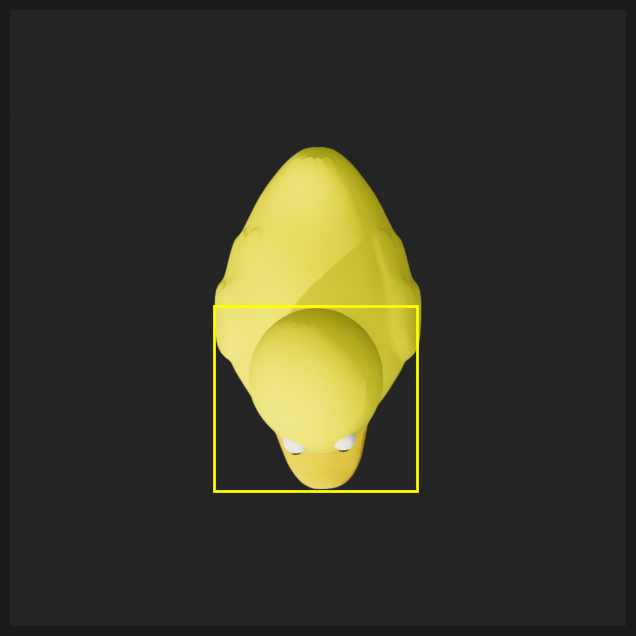

View 002 -> [282, 312, 726, 706]


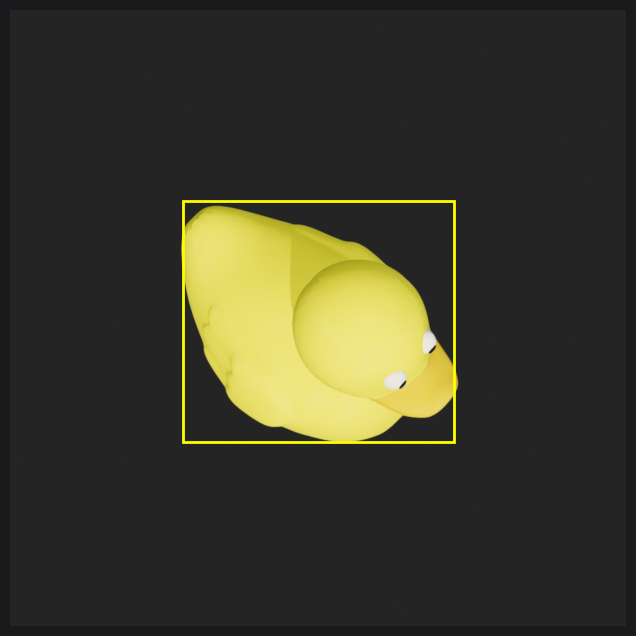

View 003 -> [328, 227, 680, 771]


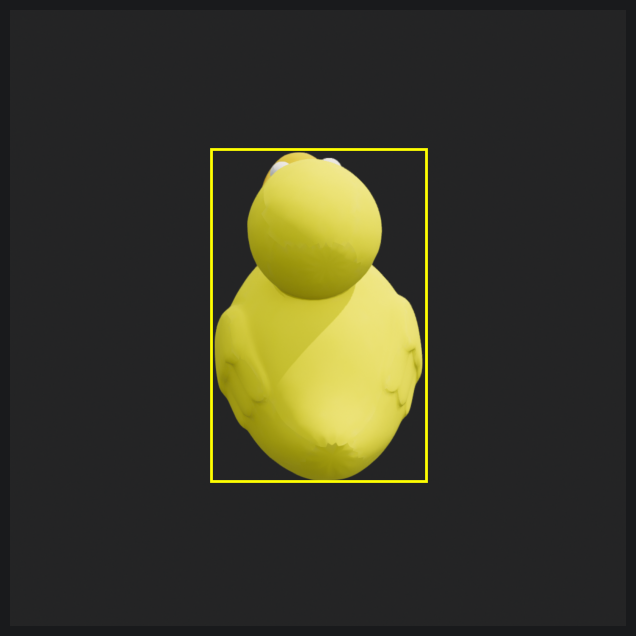

View 004 -> [302, 655, 504, 756]


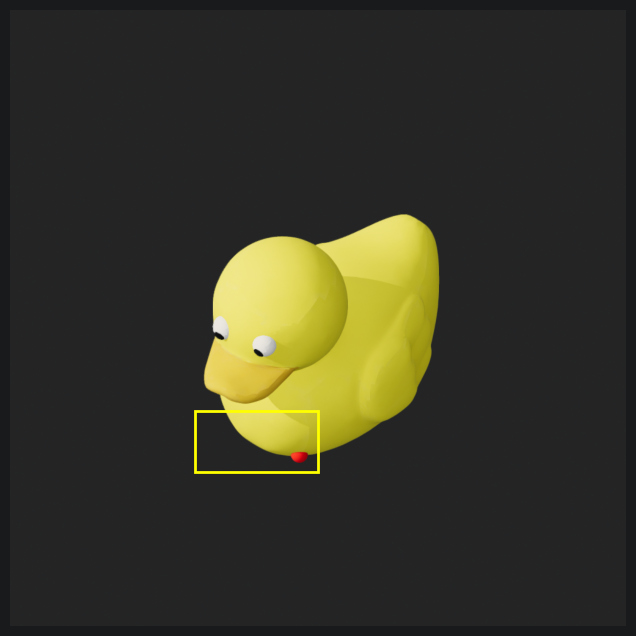

View 005 -> [302, 302, 605, 605]


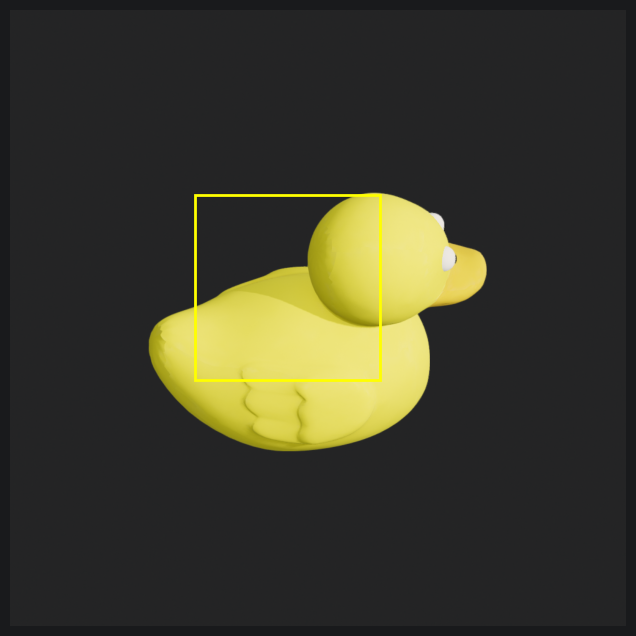

View 006 -> [312, 580, 554, 756]


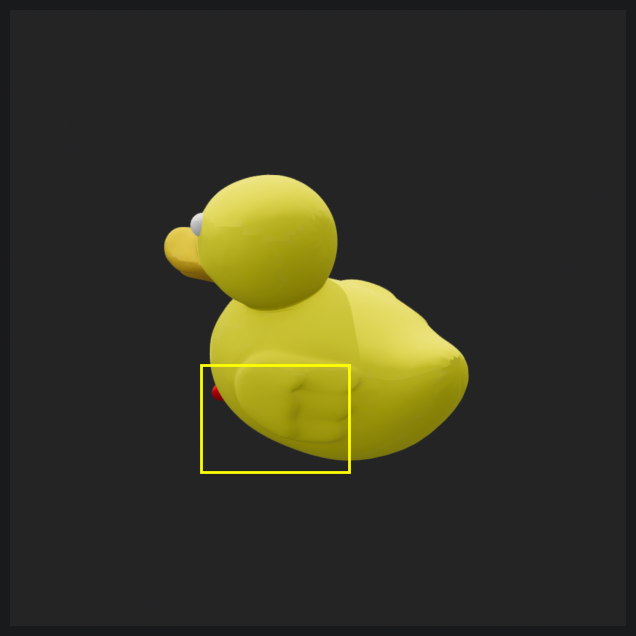

View 007 -> [403, 655, 605, 756]


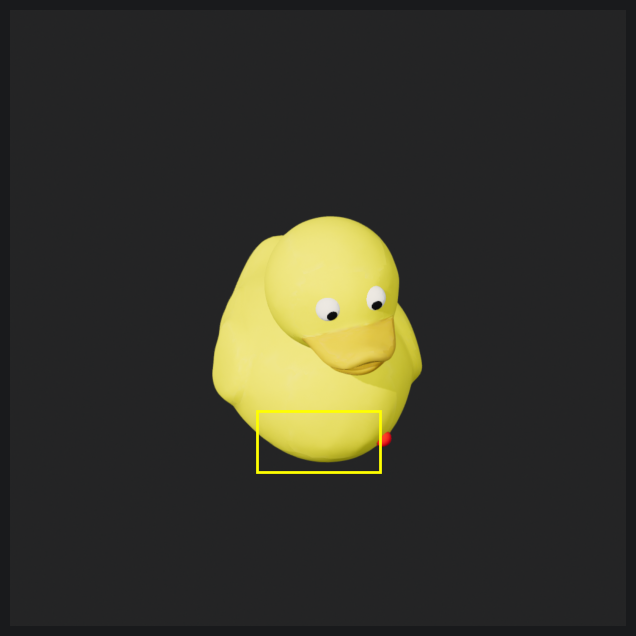

View 008 -> [328, 454, 680, 756]


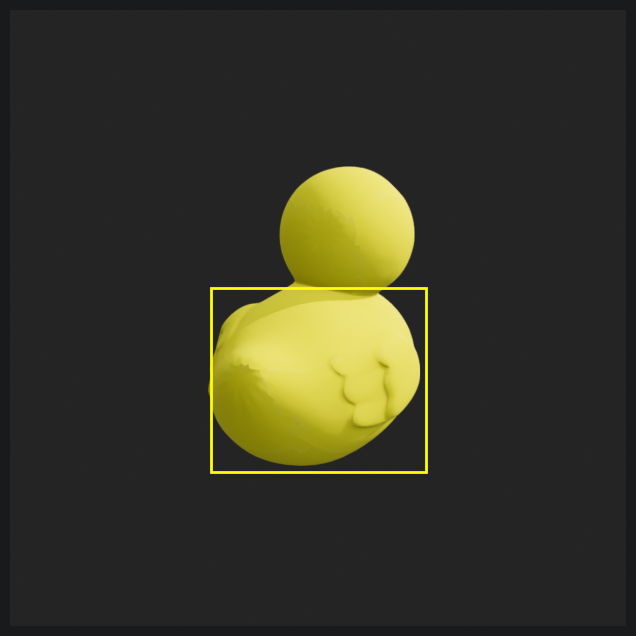

View 009 -> [328, 635, 454, 756]


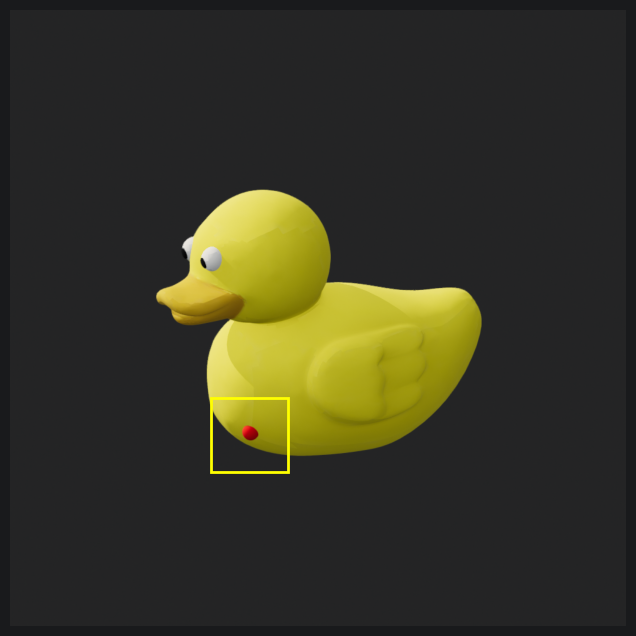

View 010 -> [242, 605, 605, 756]


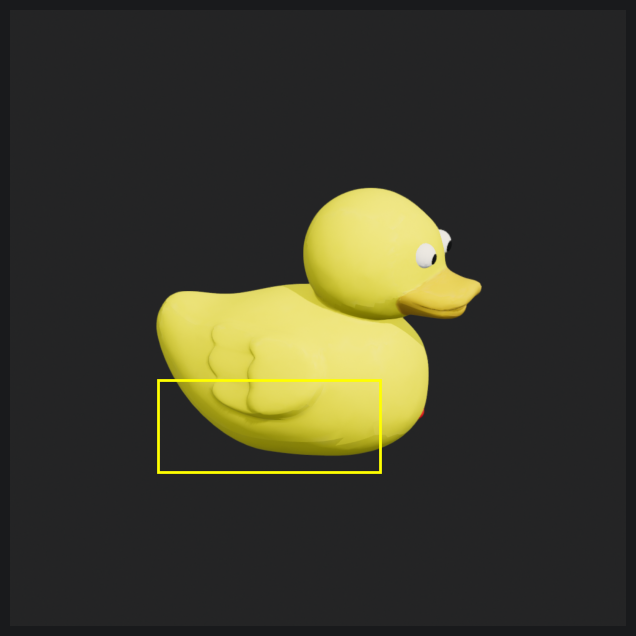

View 011 -> [328, 454, 680, 731]


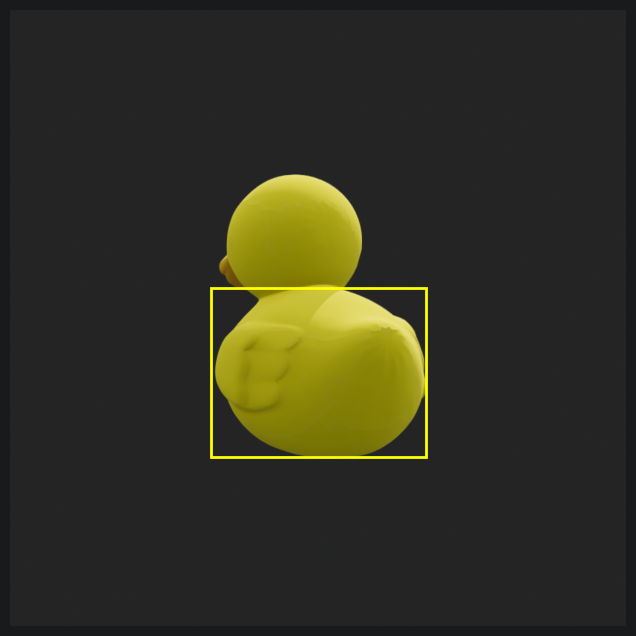

View 012 -> [328, 635, 680, 756]


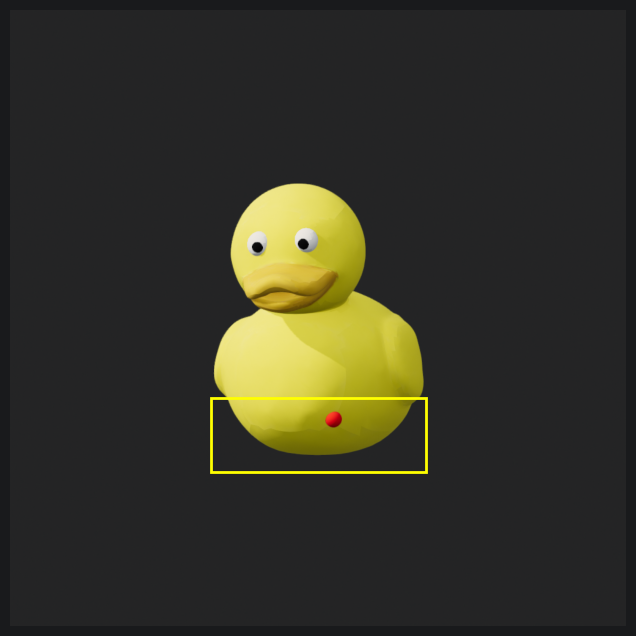

View 013 -> [302, 403, 605, 655]


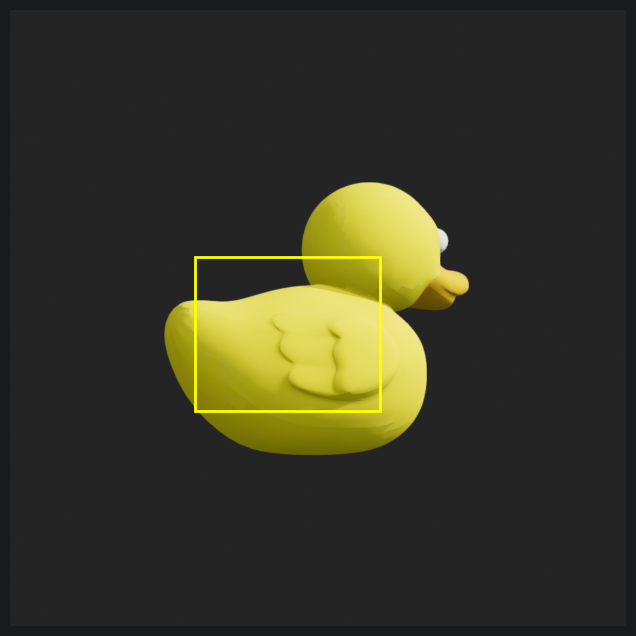

View 014 -> [282, 585, 454, 756]


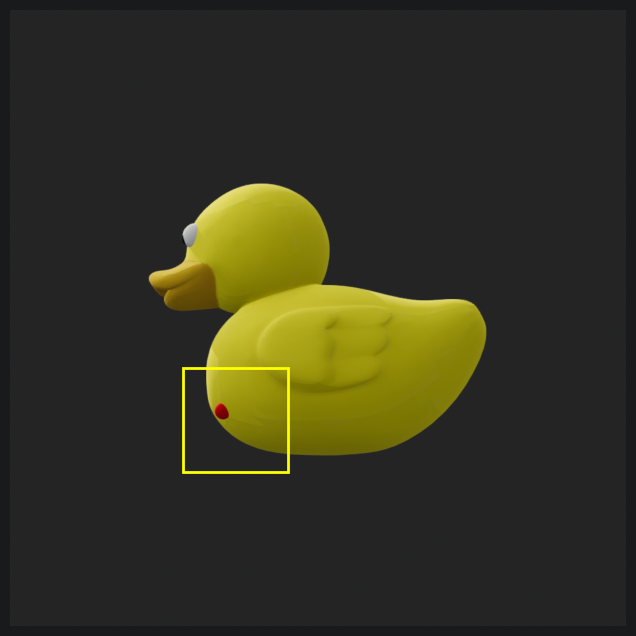

View 015 -> [302, 595, 655, 756]


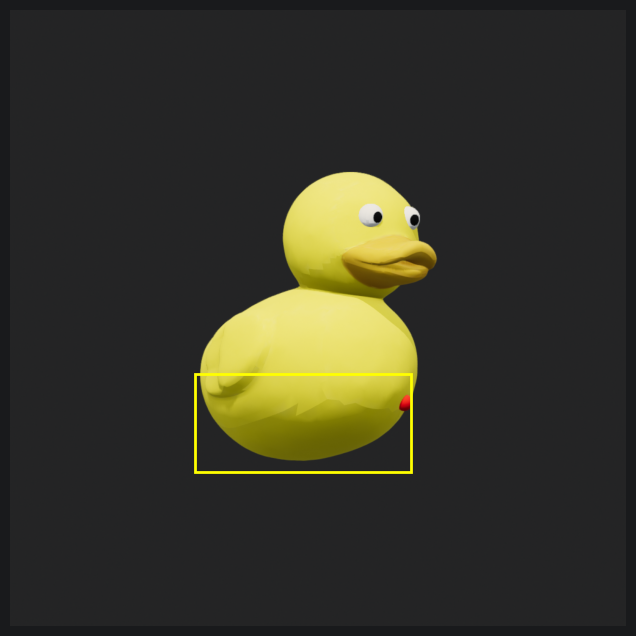

View 016 -> [328, 302, 680, 736]


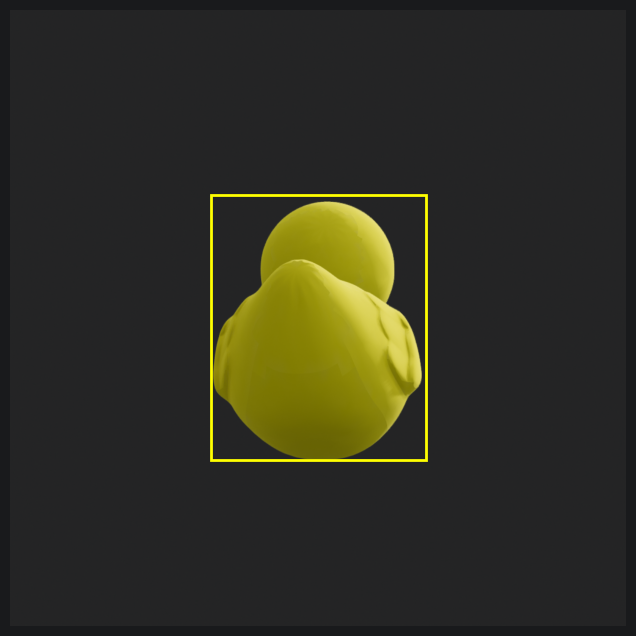

View 017 -> [328, 554, 680, 756]


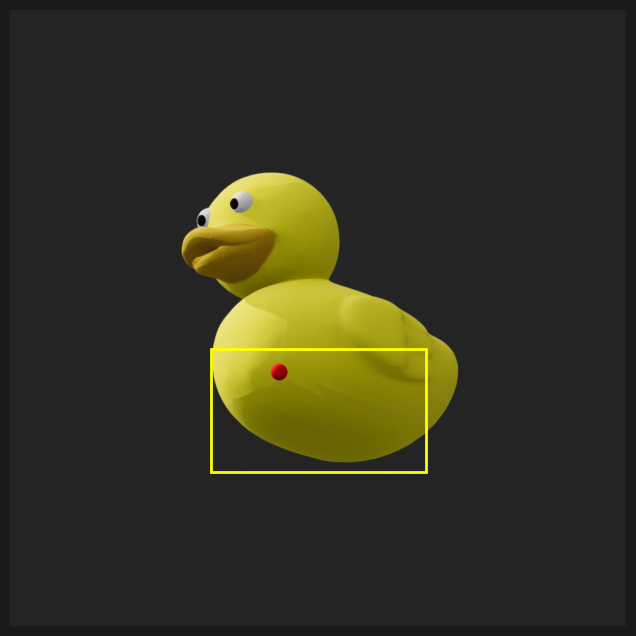

View 018 -> [227, 645, 680, 746]


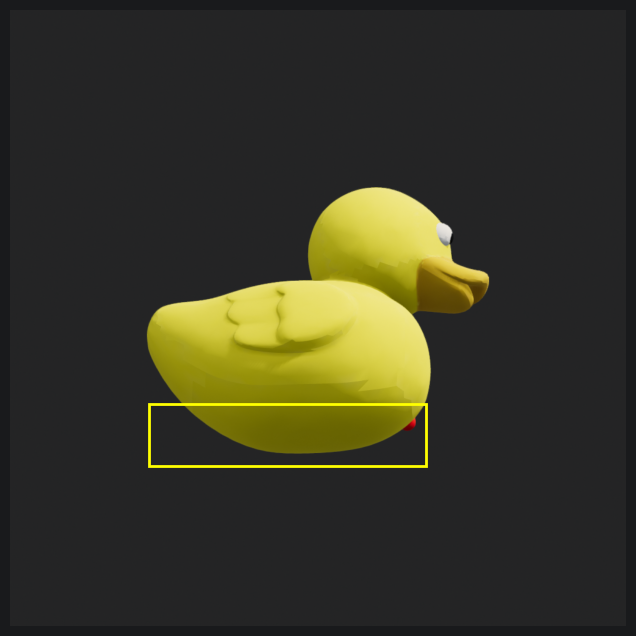

View 019 -> [282, 585, 403, 706]


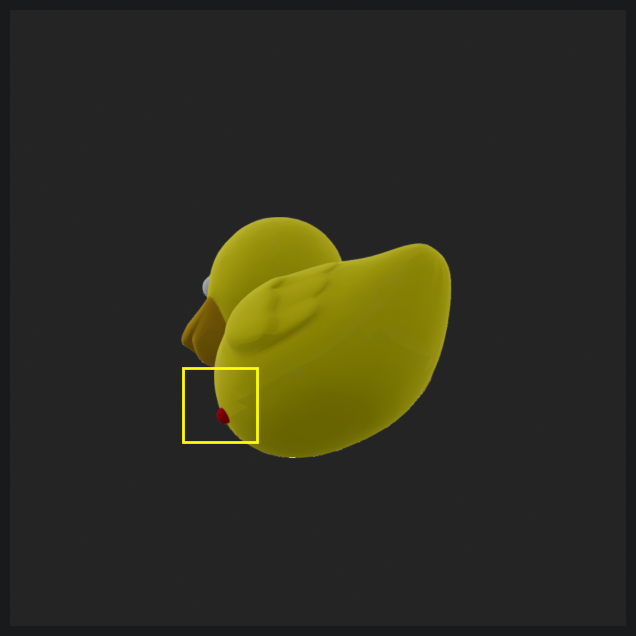

View 020 -> [328, 484, 680, 756]


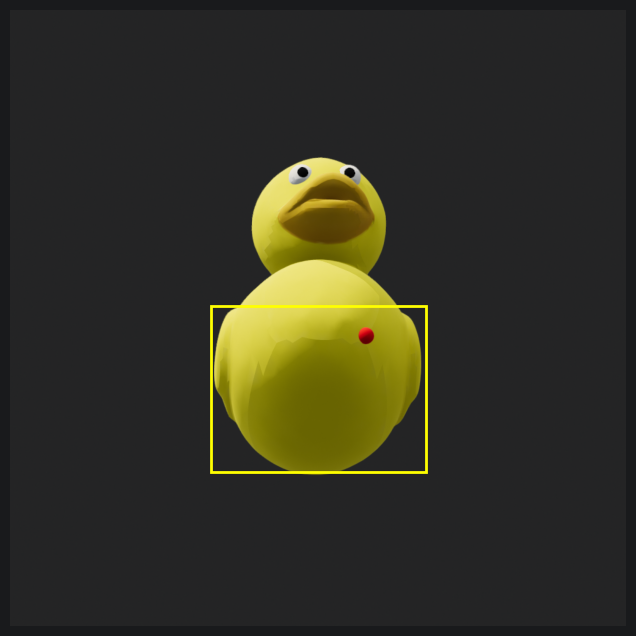

View 021 -> [302, 333, 685, 736]


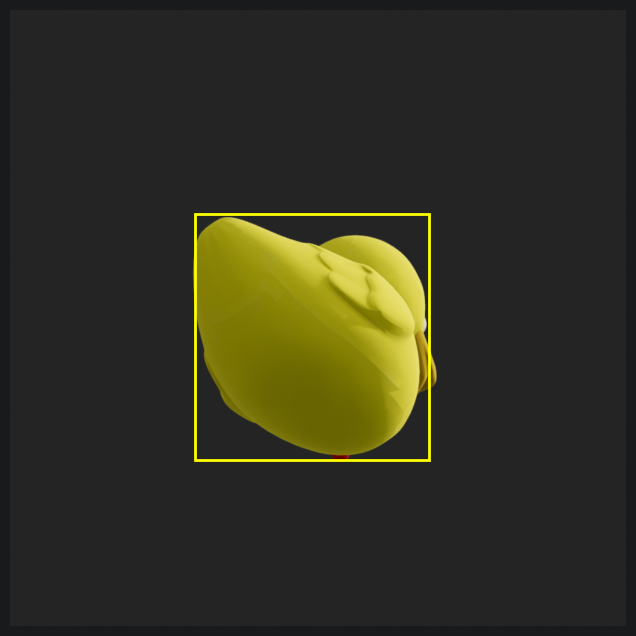

View 022 -> [282, 494, 524, 706]


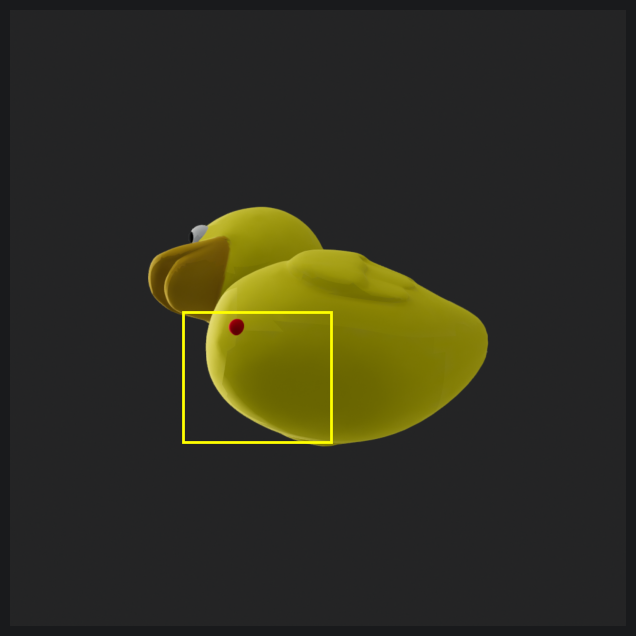

View 023 -> [302, 454, 605, 706]


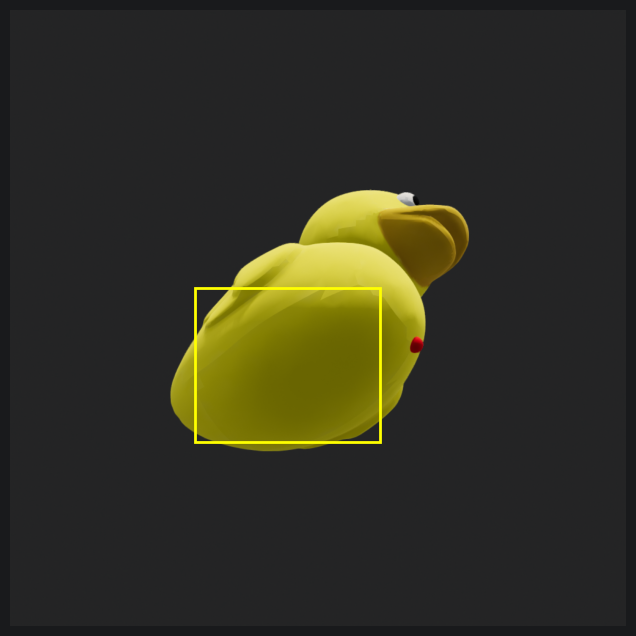

View 024 -> [328, 333, 680, 786]


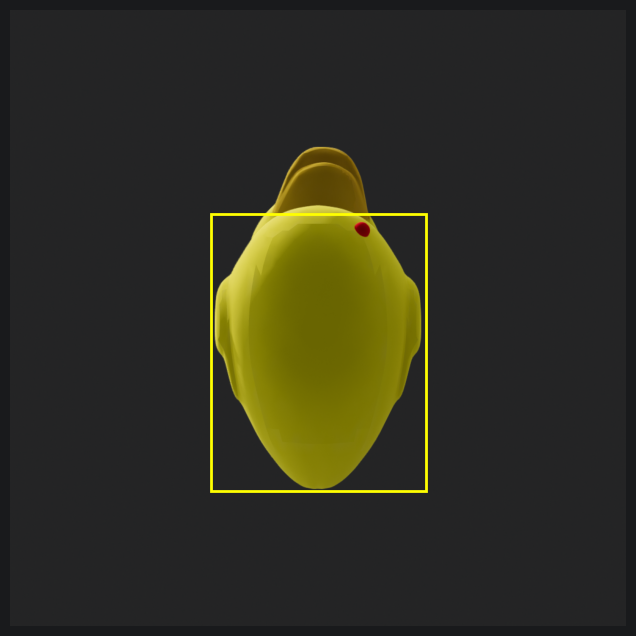

In [217]:
valid_bbox_results = [r for r in bbox_results if r["is_found"]]
print(f"Valid bbox predictions: {len(valid_bbox_results)}/{len(bbox_results)}")

for result in valid_bbox_results:
    print(f"View {result['view_idx'] + 1:03d} -> {result['bbox_2d']}")
    visualize_bbox_result(result["image_path"], result)

In [218]:
def generate_relative_insertion_bbox(
    ollama_host,
    image_path,
    reference_images,
    anchor_2d,
    user_prompt,
    model_name="qwen3-vl:8b-instruct"
):
    with Image.open(image_path) as image:
        width, height = image.size

    ax, ay = anchor_2d

    nx = round(ax / width * 1000)
    ny = round(ay / height * 1000)

    content = f"""
    User request: {user_prompt}

    Attachment anchor in Image 1:
    x = {nx}
    y = {ny}

    Predict the absolute bounding box coordinates
    of the imagined inserted component.
    """

    client = ollama.Client(host=ollama_host)

    response = client.chat(
        model=model_name,
        messages=[
            {
                "role": "system",
                "content": RELATIVE_INSERTION_BBOX_SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": content,
                "images": [
                    str(image_path),
                    *[str(p) for p in reference_images]
                ]
            }
        ],
        format="json",
        think=False,
        options={
            "temperature": 0.1,
            "num_ctx": 16384
        }
    )

    result = json.loads(response["message"]["content"])

    print("Raw VLM response:", result)

    x1 = result["xmin"] * width / 1000
    y1 = result["ymin"] * height / 1000
    x2 = result["xmax"] * width / 1000
    y2 = result["ymax"] * height / 1000

    bbox = [round(v) for v in [x1, y1, x2, y2]]

    anchor_inside = (
        x1 <= ax <= x2 and
        y1 <= ay <= y2
    )

    print("Anchor inside:", anchor_inside)

    return {
        "is_found": x1 < x2 and y1 < y2,
        "bbox_2d": bbox,
        "anchor_inside": anchor_inside
    }

### 6) Generate voxels and find most important

#### Here we first generate voxel grid, project each voxel on every view with mask. Count the relevance of voxels and keep most important ones

In [219]:
def create_voxel_grid(mesh, resolution=64, padding=0.3):
    """Create a regular voxel grid around the original mesh."""

    extent = mesh.extents.max()
    center = mesh.bounds.mean(axis=0)

    grid_size = extent * (1 + 2 * padding)
    voxel_size = grid_size / resolution

    # Generate voxel center coordinates
    axis = (
        -grid_size / 2
        + (np.arange(resolution) + 0.5) * voxel_size
    )

    x, y, z = np.meshgrid(axis, axis, axis, indexing="ij")

    voxel_points = np.stack(
        [x, y, z], axis=-1
    ).reshape(-1, 3)

    voxel_points += center

    return voxel_points, voxel_size

In [220]:
def project_points_to_image(
    points,
    eye_pos,
    center,
    extent,
    width=1008,
    height=1008,
    frame_scale=1.8,
    up=None
):
    """
    Project 3D points onto an orthographic image.
    """

    half_size = extent / 2 * frame_scale
    aspect = width / height

    # Camera coordinate system
    z_cam = np.asarray(eye_pos) - center
    z_cam /= np.linalg.norm(z_cam)

    if up is None:
        if abs(z_cam[1]) > 0.99:
            up = np.array([
                0., 0., -1. if z_cam[1] > 0 else 1.
            ])
        else:
            up = np.array([0., 1., 0.])

    x_cam = np.cross(up, z_cam)
    x_cam /= np.linalg.norm(x_cam)

    y_cam = np.cross(z_cam, x_cam)

    # Project points onto camera axes
    relative_points = points - center

    x_proj = relative_points @ x_cam
    y_proj = relative_points @ y_cam

    # Convert to pixel coordinates
    px = (
        (x_proj / (half_size * aspect) + 1)
        * width / 2 - 0.5
    )

    py = (
        (1 - y_proj / half_size)
        * height / 2 - 0.5
    )

    return np.column_stack([px, py])

In [221]:
def vote_for_voxels(
    voxel_points,
    bbox_results,
    center,
    extent,
    width=1008,
    height=1008,
    frame_scale=1.8
):
    """Calculate multi-view support for each voxel."""

    votes = np.zeros(len(voxel_points), dtype=np.int32)

    valid_results = [
        result for result in bbox_results
        if result["is_found"]
        and result["bbox_2d"] is not None
    ]

    if not valid_results:
        raise ValueError("No valid bounding boxes")

    for result in valid_results:

        projected = project_points_to_image(
            points=voxel_points,
            eye_pos=result["eye_pos"],
            center=center,
            extent=extent,
            width=width,
            height=height,
            frame_scale=frame_scale,
            up=result.get("up")
        )

        px = projected[:, 0]
        py = projected[:, 1]

        x1, y1, x2, y2 = result["bbox_2d"]

        # Check whether projected voxels are inside the box
        inside = (
            (px >= x1) &
            (px <= x2) &
            (py >= y1) &
            (py <= y2)
        )

        votes += inside.astype(np.int32)

    scores = votes / len(valid_results)

    return scores

In [222]:
base_mesh = _convert_trimesh_to_o3d(mesh)

marker = o3d.geometry.TriangleMesh.create_sphere(
    radius=base_mesh.get_axis_aligned_bounding_box()
                    .get_max_extent() * 0.025
)

marker.translate(anchor_point)

render_bbox = (
    base_mesh + marker
).get_axis_aligned_bounding_box()

render_center = render_bbox.get_center()
render_extent = render_bbox.get_max_extent()

# Restore the original camera up vectors
base_center = base_mesh.get_axis_aligned_bounding_box().get_center()

for result in bbox_results:
    result["up"] = _auto_camera_up(
        base_center,
        result["eye_pos"]
    )

In [223]:
voxel_points, voxel_size = create_voxel_grid(
    mesh,
    resolution=64,
    padding=0.3
)

voxel_scores = vote_for_voxels(
    voxel_points=voxel_points,
    bbox_results=bbox_results,
    center=render_center,
    extent=render_extent,
    frame_scale=1.8
)

print("Total voxels:", len(voxel_points))
print("Maximum score:", voxel_scores.max())

Total voxels: 262144
Maximum score: 0.9583333333333334


In [224]:
threshold = 0.7

selected_voxels = voxel_points[
    voxel_scores >= threshold
]

print("Selected voxels:", len(selected_voxels))

Selected voxels: 1901


In [225]:
def visualize_voxel_grid(mesh, voxel_points, anchor_point):
    """Visualize selected voxel centers and the attachment point."""

    cloud = trimesh.points.PointCloud(
        vertices=voxel_points,
        colors=[255, 0, 0, 255]
    )

    marker = trimesh.creation.icosphere(
        radius=mesh.extents.max() * 0.025
    )

    marker.apply_translation(anchor_point)
    marker.visual.face_colors = [255, 0, 0, 255]

    scene = trimesh.Scene([mesh, cloud, marker])
    return scene

In [226]:
visualize_voxel_grid(
    mesh,
    selected_voxels,
    anchor_point
).show()

In [227]:
for threshold in [0.5, 0.6, 0.75, 0.9]:
    count = np.sum(voxel_scores >= threshold)

    print(f"Threshold {threshold}: {count} voxels")

Threshold 0.5: 9409 voxels
Threshold 0.6: 3560 voxels
Threshold 0.75: 1324 voxels
Threshold 0.9: 22 voxels


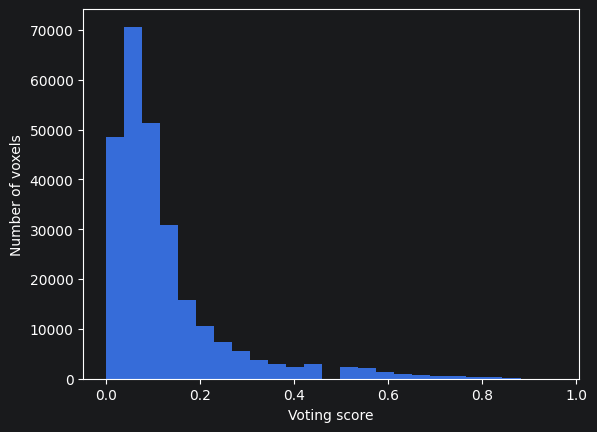

In [228]:
plt.hist(voxel_scores, bins=25)
plt.xlabel("Voting score")
plt.ylabel("Number of voxels")
plt.show()

In [229]:
def is_anchor_visible(image_path, anchor_2d, radius=30):
    image = np.array(
        Image.open(image_path).convert("RGB"),
        dtype=np.float32
    )

    height, width = image.shape[:2]
    x, y = np.round(anchor_2d).astype(int)

    if not (0 <= x < width and 0 <= y < height):
        return False

    region = image[
        max(0, y-radius):min(height, y+radius+1),
        max(0, x-radius):min(width, x+radius+1)
    ]

    red = (
        (region[:, :, 0] > 100) &
        (region[:, :, 0] > region[:, :, 1] * 1.5) &
        (region[:, :, 0] > region[:, :, 2] * 1.5)
    )

    return np.sum(red) > 10

View 001: Anchor not visible
View 002: Anchor not visible
View 003: Anchor not visible
Raw VLM response: {'xmin': 380, 'ymin': 620, 'xmax': 558, 'ymax': 800}
Anchor inside: True
View 004: [383, 625, 562, 806]


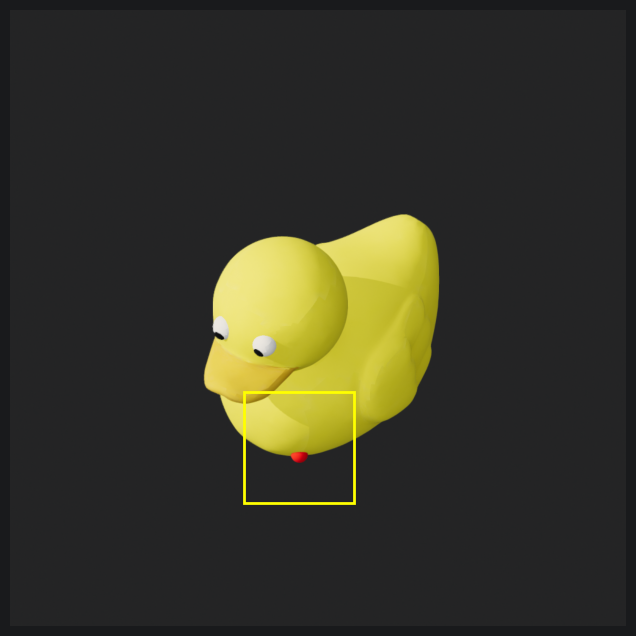

View 005: Anchor not visible
Raw VLM response: {'xmin': 280, 'ymin': 520, 'xmax': 400, 'ymax': 700}
Anchor inside: True
View 006: [282, 524, 403, 706]


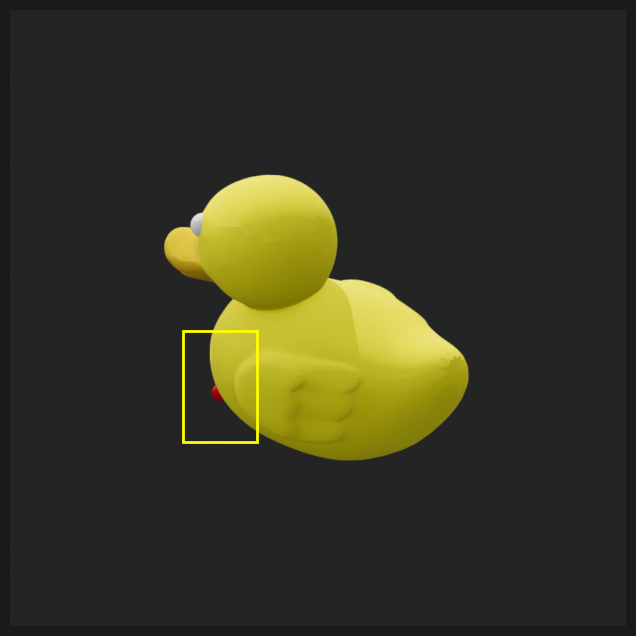

Raw VLM response: {'xmin': 550, 'ymin': 650, 'xmax': 660, 'ymax': 750}
Anchor inside: True
View 007: [554, 655, 665, 756]


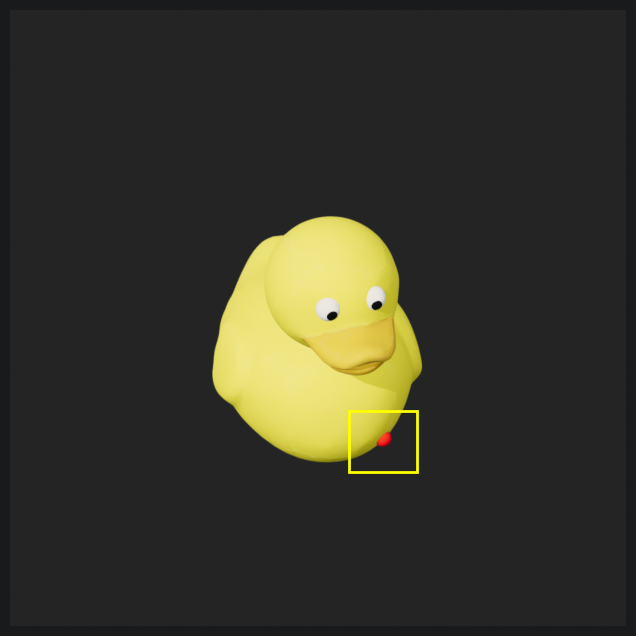

View 008: Anchor not visible
Raw VLM response: {'xmin': 280, 'ymin': 550, 'xmax': 500, 'ymax': 750}
Anchor inside: True
View 009: [282, 554, 504, 756]


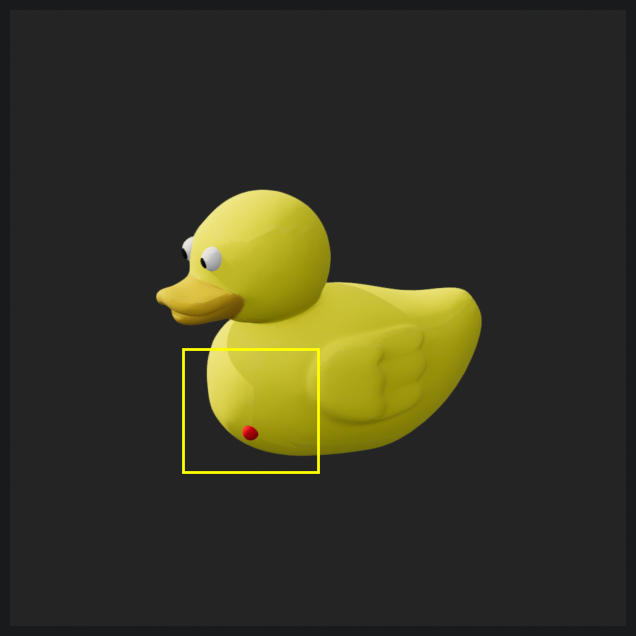

Raw VLM response: {'xmin': 550, 'ymin': 500, 'xmax': 750, 'ymax': 700}
Anchor inside: True
View 010: [554, 504, 756, 706]


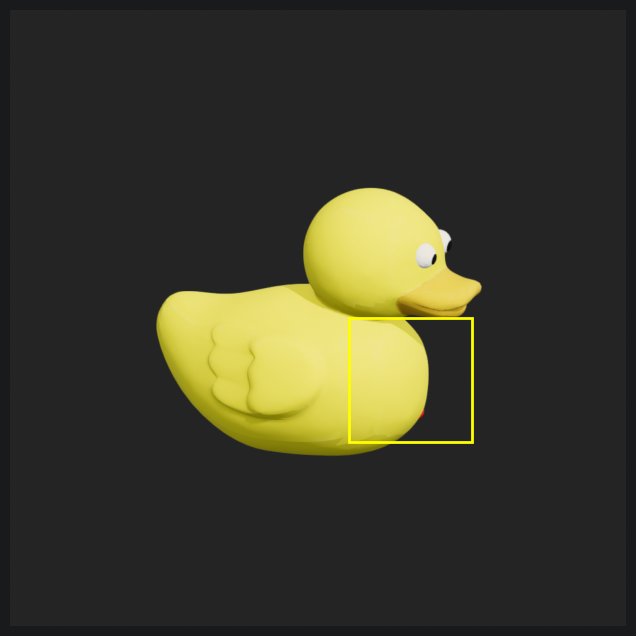

View 011: Anchor not visible
Raw VLM response: {'xmin': 450, 'ymin': 550, 'xmax': 600, 'ymax': 750}
Anchor inside: True
View 012: [454, 554, 605, 756]


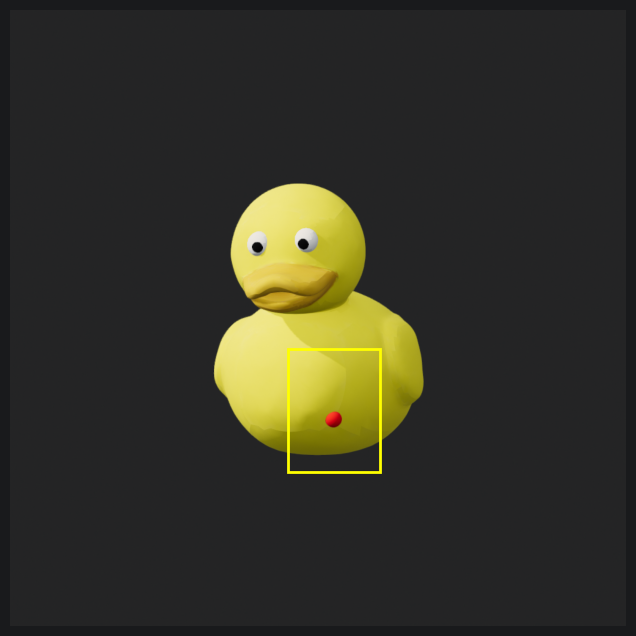

View 013: Anchor not visible
Raw VLM response: {'xmin': 280, 'ymin': 550, 'xmax': 450, 'ymax': 750}
Anchor inside: True
View 014: [282, 554, 454, 756]


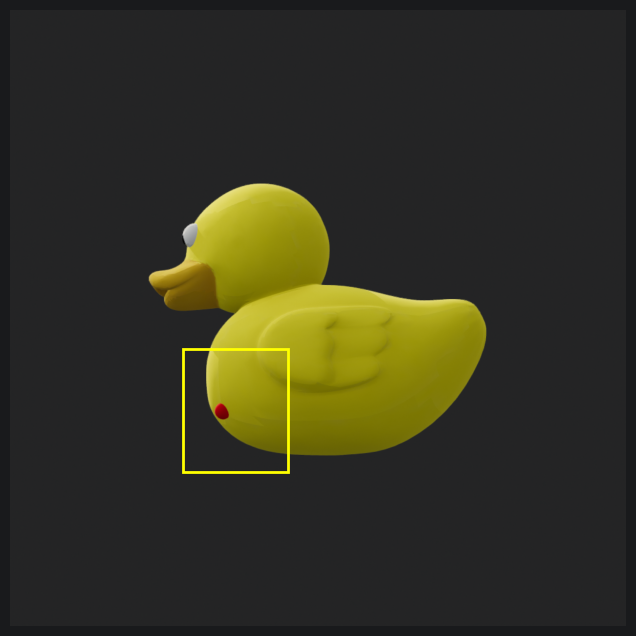

Raw VLM response: {'xmin': 550, 'ymin': 500, 'xmax': 720, 'ymax': 750}
Anchor inside: True
View 015: [554, 504, 726, 756]


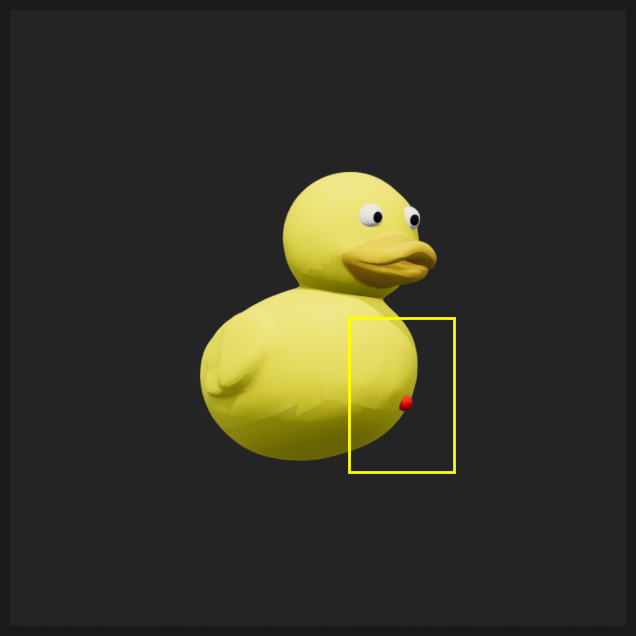

View 016: Anchor not visible
Raw VLM response: {'xmin': 350, 'ymin': 450, 'xmax': 550, 'ymax': 700}
Anchor inside: True
View 017: [353, 454, 554, 706]


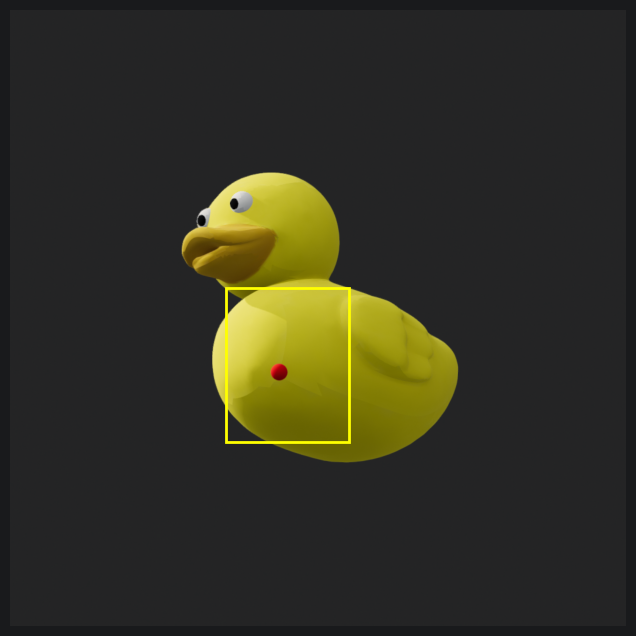

Raw VLM response: {'xmin': 550, 'ymin': 550, 'xmax': 750, 'ymax': 750}
Anchor inside: True
View 018: [554, 554, 756, 756]


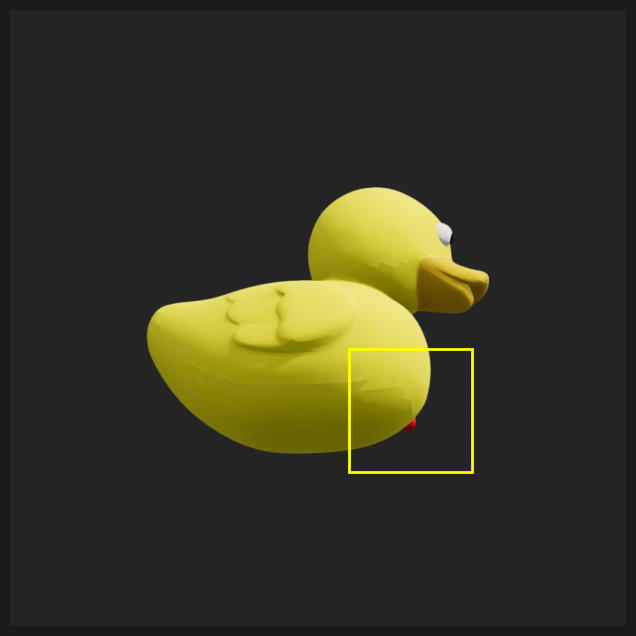

Raw VLM response: {'xmin': 280, 'ymin': 550, 'xmax': 450, 'ymax': 750}
Anchor inside: True
View 019: [282, 554, 454, 756]


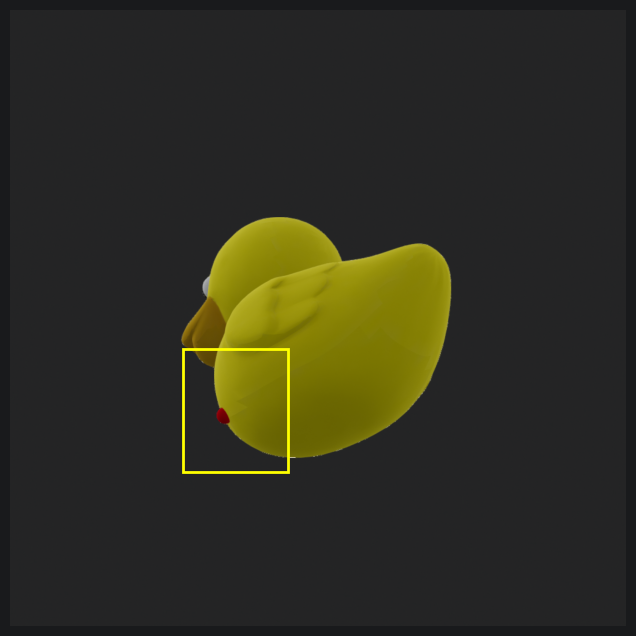

Raw VLM response: {'xmin': 480, 'ymin': 420, 'xmax': 670, 'ymax': 720}
Anchor inside: True
View 020: [484, 423, 675, 726]


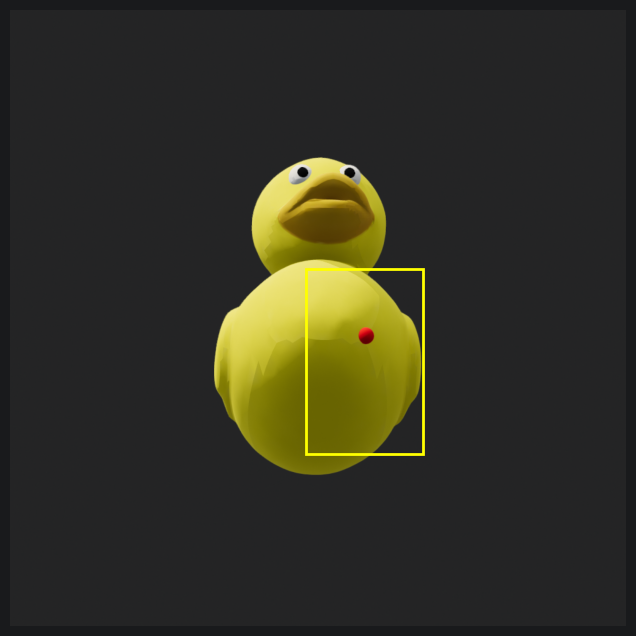

Raw VLM response: {'xmin': 450, 'ymin': 600, 'xmax': 650, 'ymax': 800}
Anchor inside: True
View 021: [454, 605, 655, 806]


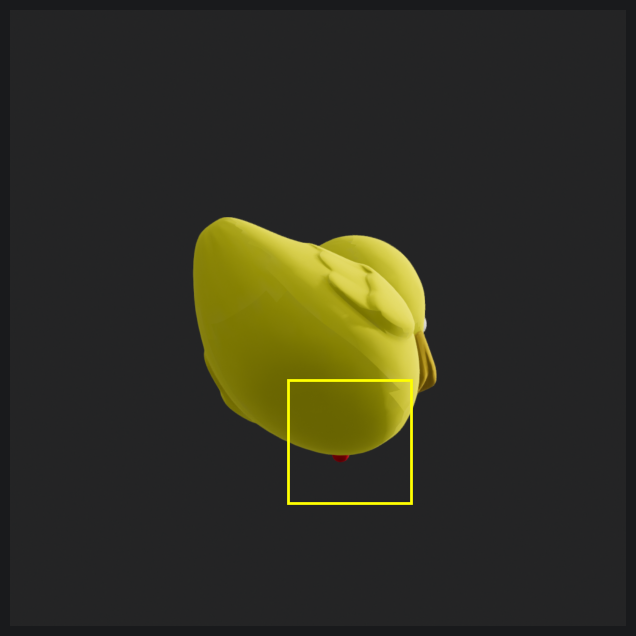

Raw VLM response: {'xmin': 280, 'ymin': 400, 'xmax': 550, 'ymax': 700}
Anchor inside: True
View 022: [282, 403, 554, 706]


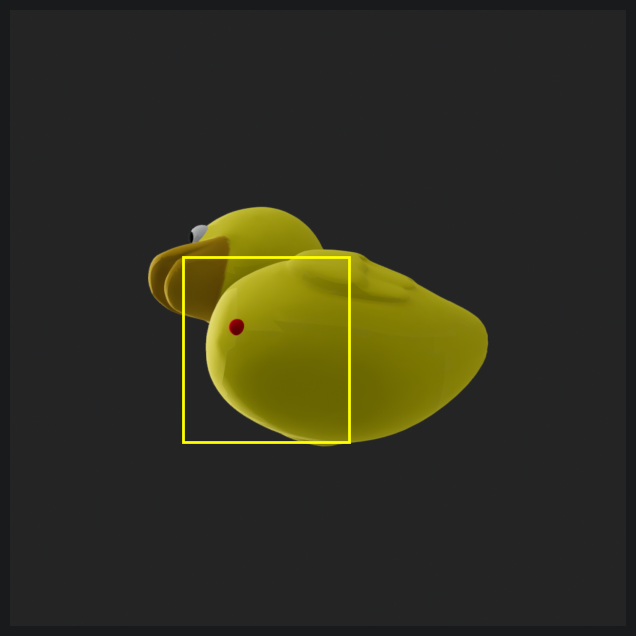

Raw VLM response: {'xmin': 550, 'ymin': 450, 'xmax': 750, 'ymax': 650}
Anchor inside: True
View 023: [554, 454, 756, 655]


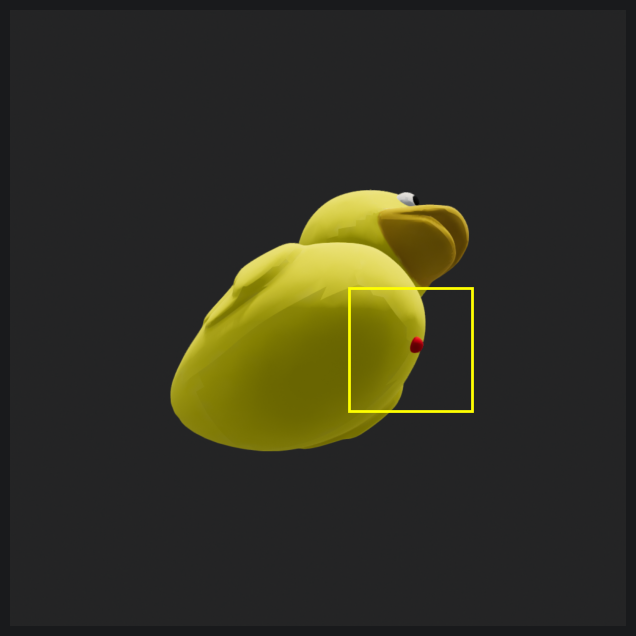

Raw VLM response: {'xmin': 450, 'ymin': 250, 'xmax': 700, 'ymax': 550}
Anchor inside: True
View 024: [454, 252, 706, 554]


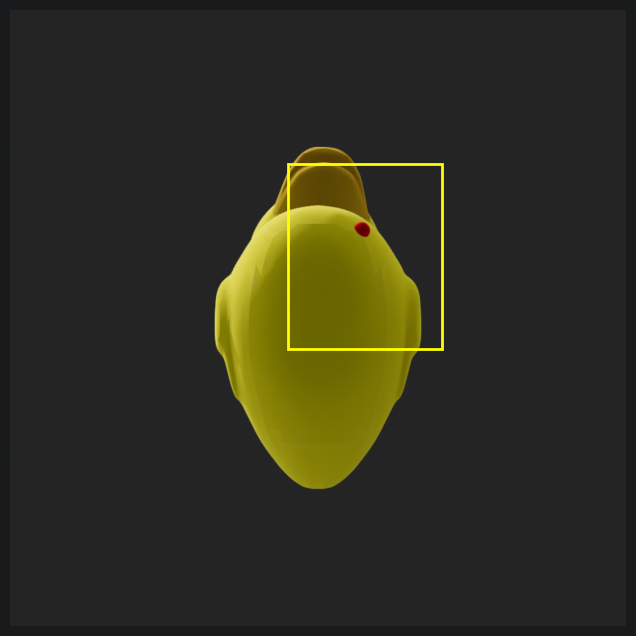

Processed views: 16/24


In [230]:
relative_bbox_results = []

for i, (eye_pos, image_path) in enumerate(anchor_rendered_info):

    camera_up = _auto_camera_up(base_center, eye_pos)

    anchor_2d = project_points_to_image(
        points=np.array([anchor_point]),
        eye_pos=eye_pos,
        center=render_center,
        extent=render_extent,
        frame_scale=1.8,
        up=camera_up
    )[0]

    # Skip views with an occluded anchor
    if not is_anchor_visible(image_path, anchor_2d):
        print(f"View {i+1:03d}: Anchor not visible")
        continue

    result = generate_relative_insertion_bbox(
        ollama_host="192.168.178.23",
        image_path=image_path,
        reference_images=inserted_object_image_paths,
        anchor_2d=anchor_2d,
        user_prompt="""
        Attach a single car wheel at the anchor.
        The wheel diameter should be approximately
        10% of the duck's total body length.
        """
    )

    result.update({
        "view_idx": i,
        "eye_pos": eye_pos,
        "image_path": image_path,
        "up": camera_up,
        "anchor_2d": anchor_2d
    })

    relative_bbox_results.append(result)

    print(f"View {i+1:03d}: {result['bbox_2d']}")

    visualize_bbox_result(image_path, result)

print(f"Processed views: {len(relative_bbox_results)}/24")

In [231]:
relative_voxel_scores = vote_for_voxels(
    voxel_points=voxel_points,
    bbox_results=relative_bbox_results,
    center=render_center,
    extent=render_extent,
    frame_scale=1.8
)

selected_voxels = voxel_points[
    relative_voxel_scores >= 0.8
]

visualize_voxel_grid(
    mesh,
    selected_voxels,
    anchor_point
).show()

### 7) Mesh fitting

#### Now we have to adjust new object offset, scale and rotation angles replace voxels with it

V'=sRV+t
s - scale
R - rotation vector
t - translation


We use voxel volumes to constraint the possible s, R and t values

In [234]:
def select_fitting_views(
    bbox_results,
    selected_views,
    n_views=3
):
    """Select relevant views for mesh fitting."""

    valid_views = {
        r["view_idx"]: r
        for r in bbox_results
        if r["is_found"]
    }

    fitting_views = [
        valid_views[i]
        for i in selected_views
        if i in valid_views
    ]

    return fitting_views[:n_views]

View 009


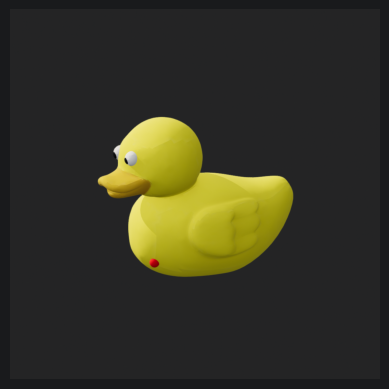

View 017


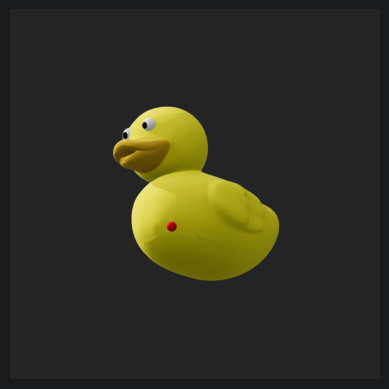

View 012


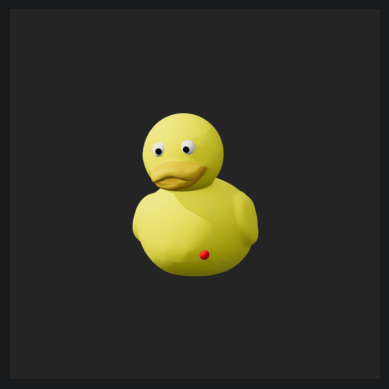

In [238]:
fitting_views = select_fitting_views(
    bbox_results=relative_bbox_results,
    selected_views=selected_views,
    n_views=3
)

for view in fitting_views:
    print(f"View {view['view_idx'] + 1:03d}")

    plt.imshow(Image.open(view["image_path"]))
    plt.axis("off")
    plt.show()